# Credit Card Fraud Detection Using Machine Learning

## Project Overview

The objective of this project is to build and evaluate machine learning models capable of detecting fraudulent credit card transactions.

Because fraud datasets are highly imbalanced, special attention is given to:
- **Imbalance handling that is compared, not assumed**: no resampling vs class weights vs SMOTE vs undersampling
- **Leakage-free, time-ordered evaluation**: train on the past, validate and test on the future
- **Metrics beyond accuracy**: PR-AUC, MCC, share of fraud *value* caught, recall at a fixed alert budget, bootstrap confidence intervals
- **A cost-aware decision threshold** that uses real transaction amounts
- **Calibration, error analysis and SHAP explanations**

## Workflow

1. Imports
2. Data Exploration
3. Data Quality Assessment
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing: feature engineering and out-of-time split
6. Modeling Pipelines and imbalance-handling ablation
7. Model Comparison and Tuning
8. Threshold Selection (cost-based)
9. Test Set Evaluation (with confidence intervals)
10. Probability Calibration
11. Error Analysis
12. Explainability (SHAP)
13. Saving the Model
14. Conclusion, Limitations and Next Steps

## 1. Imports

In [2]:
import warnings
warnings.filterwarnings('ignore')

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap                                     
from IPython.display import display, Markdown
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             precision_recall_curve, PrecisionRecallDisplay, roc_auc_score,
                             RocCurveDisplay)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier             

RANDOM_STATE = 42

## 2. Data Exploration

### Dataset

The dataset contains anonymized credit card transactions made by European cardholders over two days.

**Features:**
- **V1–V28**: Principal components obtained using PCA
- **Time**: Seconds elapsed between each transaction and the *first* transaction in the dataset (not a clock time)
- **Amount**: Transaction amount
- **Class**:
  - 0 → Legitimate Transaction
  - 1 → Fraudulent Transaction

The dataset is highly imbalanced, making fraud detection a challenging classification problem.

In [3]:
# Load the credit card transactions dataset
df = pd.read_csv('../data/creditcard.csv')

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\n--- Dataset Info ---")
df.info()

Dataset Shape: (284807, 31)

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [7]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

## 3. Data Quality Assessment

In [8]:
print(f"Shape: {df.shape}")
print(f"Fraud %: {df['Class'].mean()*100:.3f}%")
print(df['Class'].value_counts())

Shape: (284807, 31)
Fraud %: 0.173%
Class
0    284315
1       492
Name: count, dtype: int64


#### Observation

Only **0.173%** of the transactions are fraudulent.

This confirms that the dataset is **highly imbalanced**, making accuracy an unreliable evaluation metric.

For this reason, precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC will be emphasized later in the project.

In [9]:
# Check for missing values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
# Check for duplicate records
duplicates = df.duplicated().sum()
print(f"Duplicate Records: {duplicates}")

# Remove duplicates before splitting, so identical rows cannot end up in both train and test
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after de-duplication: {df.shape}")
print(df['Class'].value_counts().rename({0: 'Legit', 1: 'Fraud'}).to_string())
print(f"Fraud rate: {df['Class'].mean()*100:.3f}%")

Duplicate Records: 1081
Shape after de-duplication: (283726, 31)
Class
Legit    283253
Fraud       473
Fraud rate: 0.167%


## 4. Exploratory Data Analysis (EDA)

This section explores the dataset to better understand feature distributions, class imbalance, and relationships between variables. These insights help guide preprocessing and model selection.

#### Observations

- Transaction amounts are highly right-skewed, with most transactions involving relatively small amounts.
- A small number of transactions have very large amounts, indicating the presence of outliers.
- Transaction time is spread across the observation period and does not appear uniformly distributed.

Text(0.5, 0, 'Transaction Class')

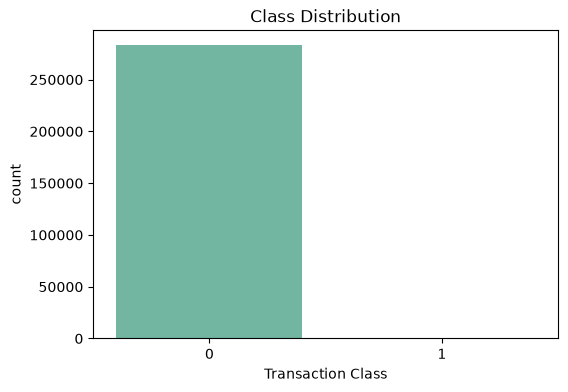

In [11]:
# Visualize the distribution of legitimate and fraudulent transactions
plt.figure(figsize=(6,4))
sns.countplot(x="Class", data=df, palette='Set2')
plt.title("Class Distribution")
plt.xlabel("Transaction Class")

#### Observation

The dataset is extremely imbalanced. Fraudulent transactions account for only about **0.17%** of all observations. Therefore, evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC are more appropriate than accuracy.

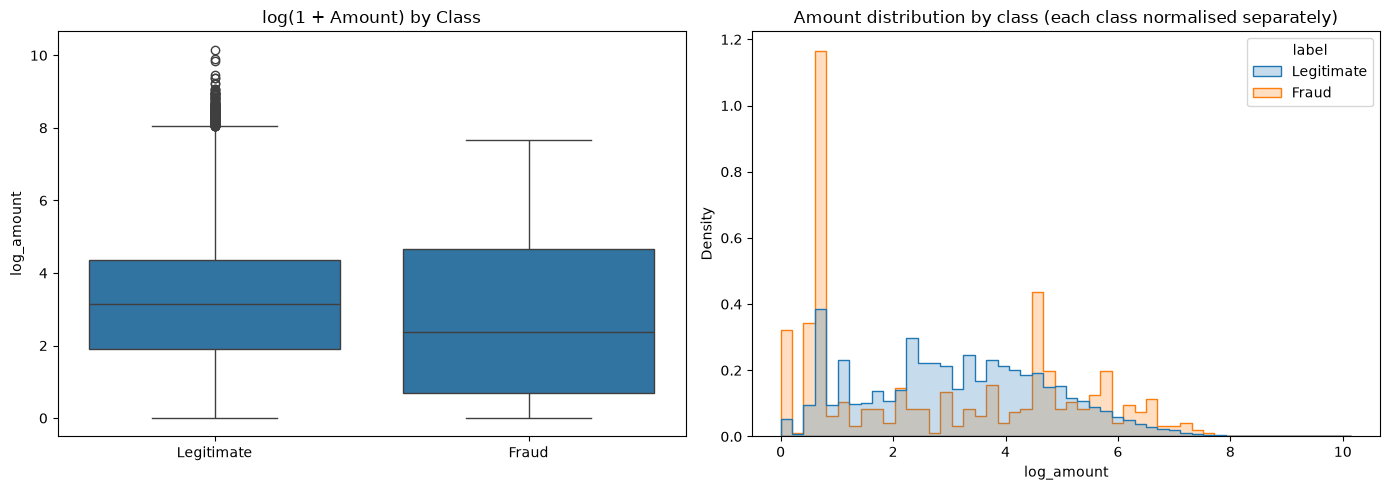

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [12]:
# Compare transaction amounts for legitimate and fraudulent transactions
# Transaction amount by class on a log scale (the raw scale is dominated by a few huge legit transactions)
amt_df = pd.DataFrame({
    'label': df['Class'].map({0: 'Legitimate', 1: 'Fraud'}),
    'log_amount': np.log1p(df['Amount']),
})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='label', y='log_amount', data=amt_df, order=['Legitimate', 'Fraud'], ax=ax[0])
ax[0].set_title('log(1 + Amount) by Class')
ax[0].set_xlabel('')
sns.histplot(data=amt_df, x='log_amount', hue='label', hue_order=['Legitimate', 'Fraud'],
             stat='density', common_norm=False, bins=50, element='step', ax=ax[1])
ax[1].set_title('Amount distribution by class (each class normalised separately)')
plt.tight_layout()
plt.show()

display(df.groupby('Class')['Amount'].describe().round(2))

(0.0, 172792.0)

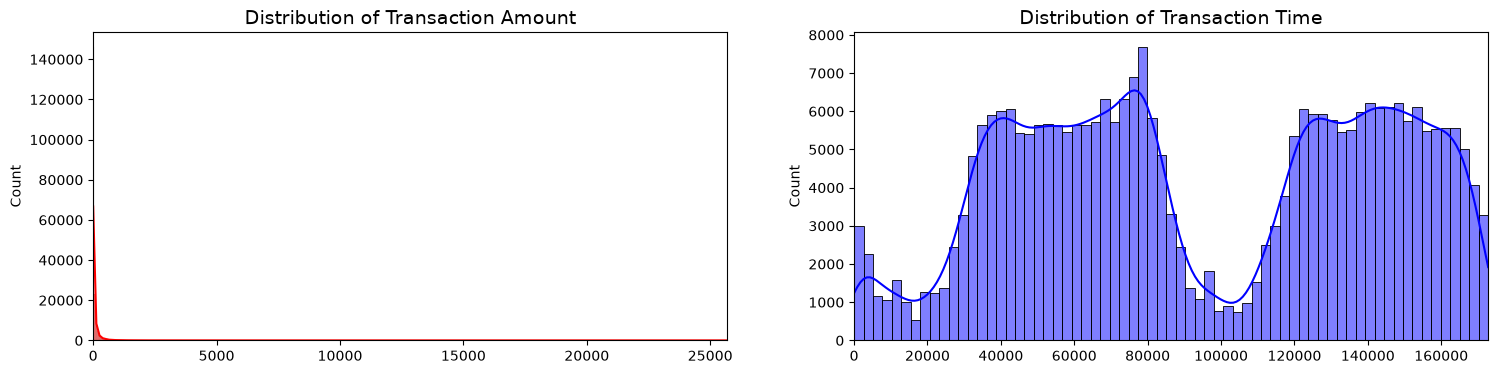

In [13]:
# Create two subplots to visualize the distributions of transaction amount and transaction time
fig, ax = plt.subplots(1, 2, figsize=(18,4))

# The amount and time features
amount_val = df['Amount'].values
time_val = df['Time'].values

# Transaction amount distribution
sns.histplot(amount_val, ax=ax[0], color='r', kde=True)
ax[0].set_title('Distribution of Transaction Amount', fontsize=14)
ax[0].set_xlim([min(amount_val), max(amount_val)])

# Transaction time distribution
sns.histplot(time_val, ax=ax[1], color='b', kde=True)
ax[1].set_title('Distribution of Transaction Time', fontsize=14)
ax[1].set_xlim([min(time_val), max(time_val)])

- V1 to V28 are PCA components, so they are uncorrelated by construction and correalation heatmap will be almost entirely blank. A sorted bar chart of correlation with Class is more informative.

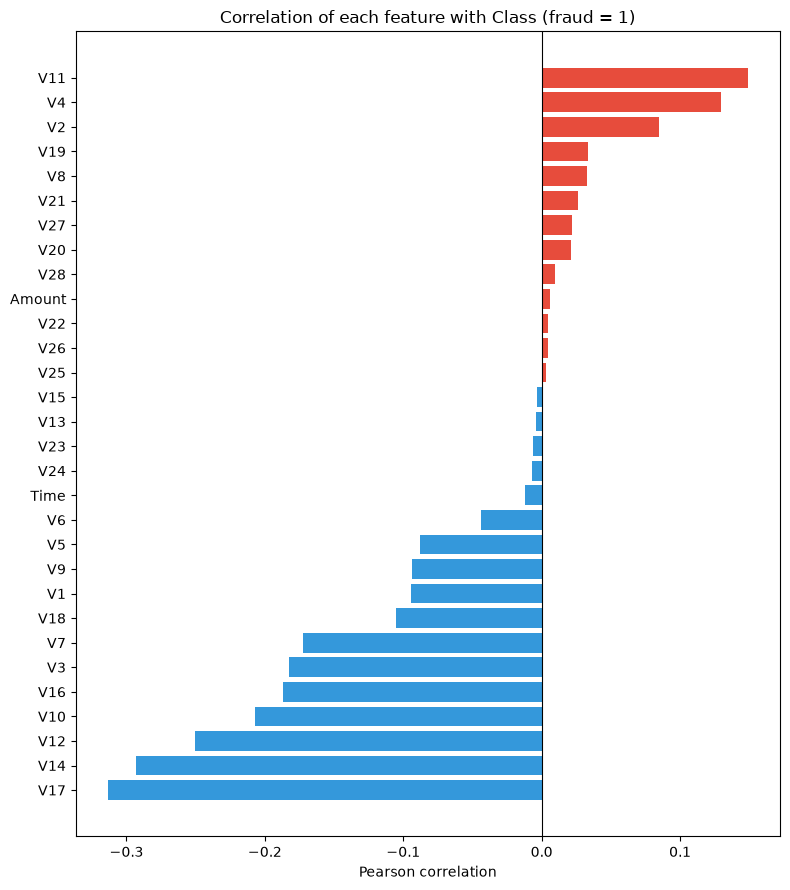

In [14]:
# Correlation of every feature with the target, sorted
corr_with_class = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()

plt.figure(figsize=(8, 9))
plt.barh(corr_with_class.index, corr_with_class.values,
         color=['#3498db' if v < 0 else '#e74c3c' for v in corr_with_class.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each feature with Class (fraud = 1)')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

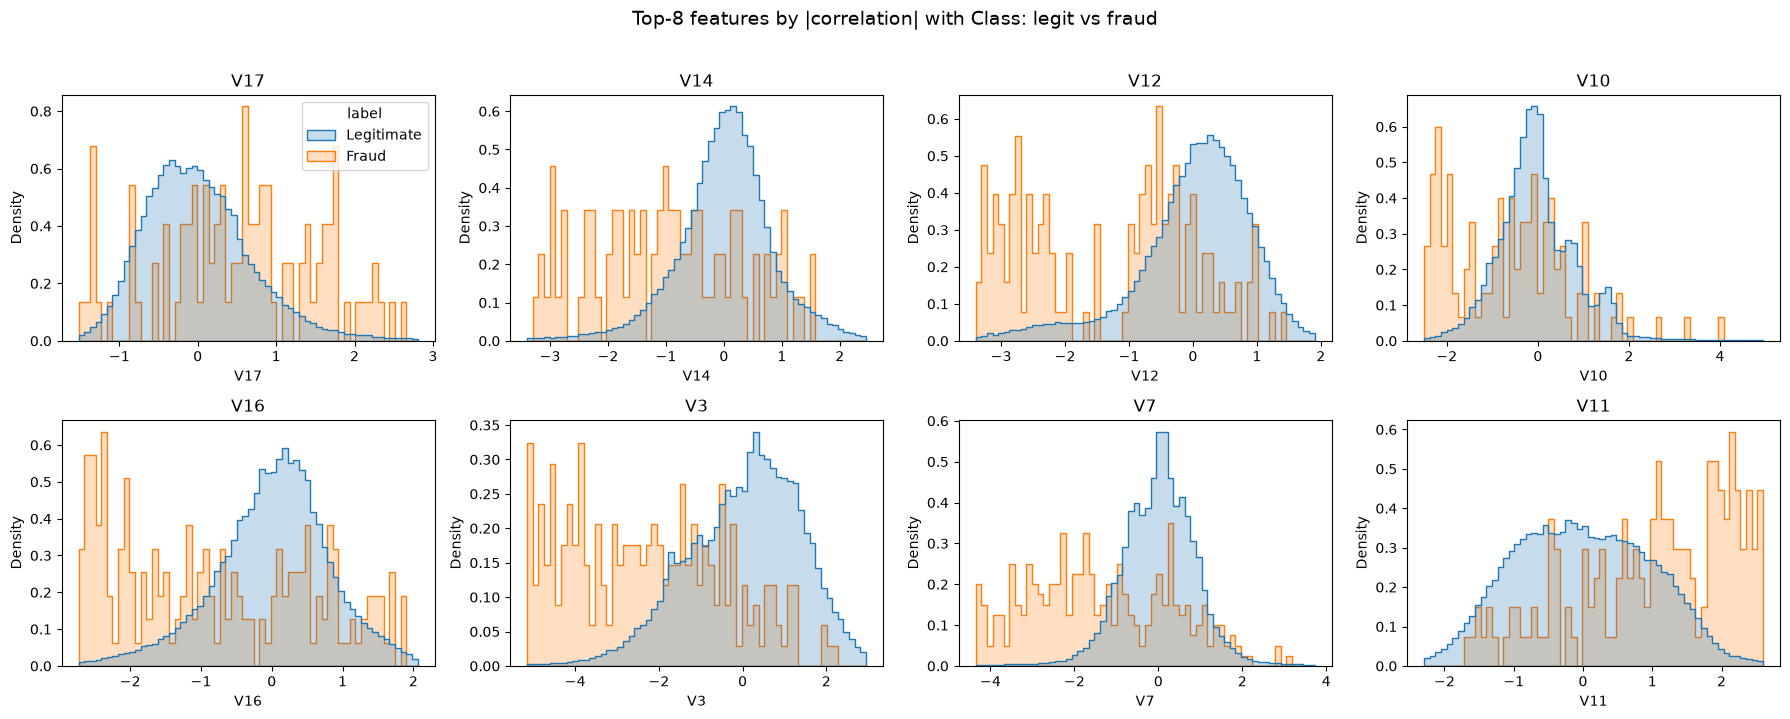

In [15]:
# Distribution of the 8 features most correlated with Class, fraud vs legit (each class normalised separately)
corr_abs = df.corr(numeric_only=True)['Class'].drop('Class').abs()
top_feats = corr_abs.sort_values(ascending=False).head(8).index.tolist()
feat_df = df[top_feats].assign(label=df['Class'].map({0: 'Legitimate', 1: 'Fraud'}))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for f, ax in zip(top_feats, axes.ravel()):
    lo, hi = df[f].quantile([0.005, 0.995])                    # zoom to the bulk of the data
    sns.histplot(data=feat_df, x=f, hue='label', hue_order=['Legitimate', 'Fraud'], stat='density',
                 common_norm=False, bins=60, binrange=(lo, hi), element='step', ax=ax,
                 legend=(f == top_feats[0]))
    ax.set_title(f)
plt.suptitle('Top-8 features by |correlation| with Class: legit vs fraud', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

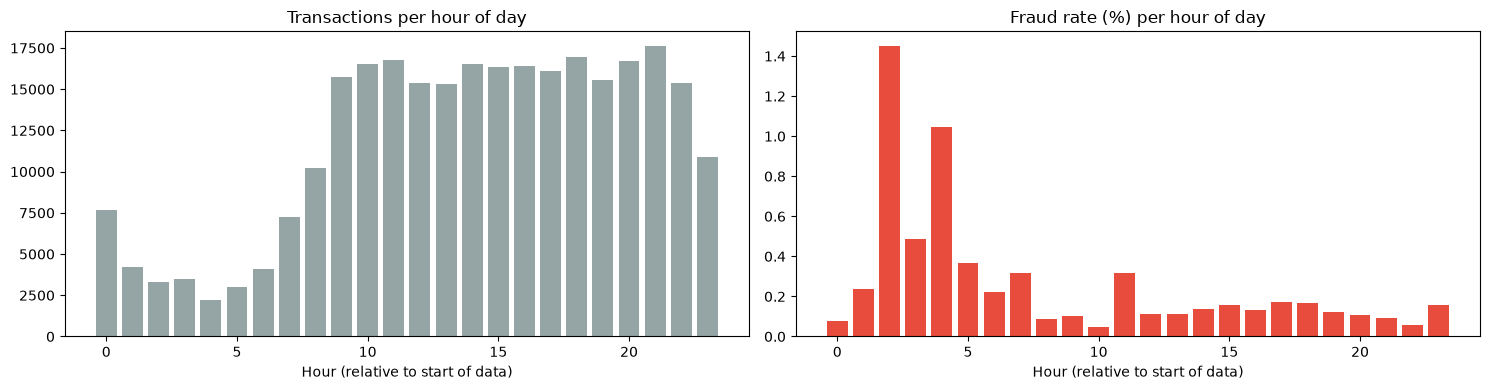

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
transactions,7647.000,4208.000,3308.000,3487.000,2204.000,2988.000,4082.00,7233.000,10232.000,15767.000,...,16520.000,16374.000,16396.000,16130.000,16959.000,15566.000,16705.000,17629.000,15378.000,10883.000
frauds,6.000,10.000,48.000,17.000,23.000,11.000,9.00,23.000,9.000,16.000,...,23.000,26.000,22.000,28.000,28.000,19.000,18.000,16.000,9.000,17.000
fraud_rate_%,0.078,0.238,1.451,0.488,1.044,0.368,0.22,0.318,0.088,0.101,...,0.139,0.159,0.134,0.174,0.165,0.122,0.108,0.091,0.059,0.156


In [16]:
# Volume and fraud rate by hour of day. Time is "seconds since the first transaction",
# so the hour is relative to the start of the data, not wall-clock time.
hour_of_day = ((df['Time'] // 3600) % 24).astype(int).rename('hour')
by_hour = df.groupby(hour_of_day).agg(transactions=('Class', 'size'), frauds=('Class', 'sum'))
by_hour['fraud_rate_%'] = 100 * by_hour['frauds'] / by_hour['transactions']

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(by_hour.index, by_hour['transactions'], color='#95a5a6')
ax[0].set_title('Transactions per hour of day')
ax[0].set_xlabel('Hour (relative to start of data)')
ax[1].bar(by_hour.index, by_hour['fraud_rate_%'], color='#e74c3c')
ax[1].set_title('Fraud rate (%) per hour of day')
ax[1].set_xlabel('Hour (relative to start of data)')
plt.tight_layout()
plt.show()

display(by_hour.T.round(3))

### EDA takeaways

- **Imbalance:** only ~0.17 % of transactions are fraud, so accuracy is meaningless. PR-AUC, precision/recall and value-based metrics are used instead.
- **Amount:** heavily right-skewed (note the log scale). Fraud amounts tend to be small, so Amount alone separates the classes poorly (see the per-class table). It still matters for *cost*, because a missed fraud costs its amount, so it is used in the threshold selection (section 8).
- **Time:** the histogram shows a clear day/night cycle, and `Time` is "seconds since the first transaction", not a clock time. Raw `Time` cannot generalise to a later period, so section 5 replaces it with cyclical hour-of-day features.
- **Features:** V1–V28 are PCA components, so they are uncorrelated with each other and no single one separates fraud well. That is why the sorted bar chart replaces the 30×30 heatmap. The features most correlated with `Class` should reappear as the most important ones in the SHAP analysis (section 12).
- **Hour of day:** the fraud *rate* per hour is noisy (only a few dozen frauds per hourly bucket) and is often highest in the quiet hours, when legitimate volume is low. Treat it as a weak signal.

## 5. Data Preprocessing

### 5.1 Features
- **`Time` → cyclical hour of day (`hour_sin`, `hour_cos`).** Raw `Time` is "seconds since the first transaction" and only grows, so in a time-ordered split the test period lies outside anything seen in training, and tree models cannot extrapolate. The daily cycle seen in the EDA is the reusable signal. Sin/cos encoding makes 23:59 and 00:01 neighbours.
- **`Amount` → `log_amount = log(1 + Amount)`** to tame the heavy right tail (helps linear models, harmless for trees). The raw amounts are kept aside, only for cost and value-based metrics.
- **V1–V28** are used as they are (already PCA components).
- Feature creation is stateless (nothing is learned from the data), so doing it before the split cannot leak information.


In [17]:
def make_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Raw columns (Time, V1..V28, Amount) -> model features. Stateless, so it is safe to apply before splitting."""
    out = raw[[f'V{i}' for i in range(1, 29)]].copy()
    out['log_amount'] = np.log1p(raw['Amount'])
    tod = (raw['Time'] % 86400) / 86400                  # position inside the 24 h cycle, 0..1
    out['hour_sin'] = np.sin(2 * np.pi * tod)
    out['hour_cos'] = np.cos(2 * np.pi * tod)
    return out

### 5.2 Out-of-time (OOT) split
Transactions are sorted by `Time` and split **70 % train / 15 % validation / 15 % test**.

A random split can train on transactions that happen *after* some of the test transactions, which never happens in production. Here:
- **Train** = the past. Everything is fitted on it.
- **Validation** = the next block. Used for model selection, tuning and the decision threshold.
- **Test** = the "far future". Used once, at the end.

In [18]:
# Sort chronologically: never train on the future of the data you test on
df_sorted = df.sort_values('Time', kind='stable').reset_index(drop=True)
X_all, y_all = make_features(df_sorted), df_sorted['Class']
amount_all = df_sorted['Amount']                         # raw amounts, kept for cost / value-based metrics only

n_rows = len(df_sorted)
train_end, val_end = int(n_rows * 0.70), int(n_rows * 0.85)

X_train, y_train = X_all.iloc[:train_end], y_all.iloc[:train_end]
X_val, y_val, amt_val = X_all.iloc[train_end:val_end], y_all.iloc[train_end:val_end], amount_all.iloc[train_end:val_end].values
X_test, y_test, amt_test = X_all.iloc[val_end:], y_all.iloc[val_end:], amount_all.iloc[val_end:].values
raw_test = df_sorted.iloc[val_end:]                      # raw columns of the test block (used to verify the saved model)

split_summary = pd.DataFrame({
    'rows': [len(X_train), len(X_val), len(X_test)],
    'frauds': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    'fraud_rate_%': [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
    'starts_at_hour': [df_sorted['Time'].iloc[0] / 3600, df_sorted['Time'].iloc[train_end] / 3600,
                       df_sorted['Time'].iloc[val_end] / 3600],
}, index=['Train (past)', 'Validation', 'Test (future)'])
display(split_summary.round(3))
print(f'{X_train.shape[1]} features: V1-V28 + {list(X_train.columns[28:])}   (raw Time and raw Amount are not used)')

,rows,frauds,fraud_rate_%,starts_at_hour
Train (past),198608,366,0.184,0.000
Validation,42559,55,0.129,36.918
Test (future),42559,52,0.122,42.033


31 features: V1-V28 + ['log_amount', 'hour_sin', 'hour_cos']   (raw Time and raw Amount are not used)



## 6. Modeling Pipelines

### One imbalance fix per pipeline
The earlier version combined SMOTE with `class_weight='balanced'` / `scale_pos_weight`. SMOTE already makes the training classes 1:1, so class weights on top of it either do nothing (`balanced` → all weights equal 1) or double-count the imbalance (`scale_pos_weight ≈ 600` after SMOTE). That also made the XGBoost comparison unfair. Every pipeline below uses exactly **one** of:

| strategy | what it does |
|---|---|
| `none` | train on the raw, imbalanced data |
| `class_weight` | re-weights the loss (`class_weight='balanced'` or `scale_pos_weight`) |
| `smote` | adds synthetic fraud samples (training folds only, because it sits inside the pipeline) |
| `undersample` | randomly drops legit rows to 10 legit : 1 fraud |

Feature scaling is applied only for logistic regression. Tree models are scale-invariant, which also keeps the SHAP plots in original feature units.

The shared helper functions defined next (cost curve, `evaluate`, F-beta threshold, alert-budget recall) are reused in sections 7 to 9.

In [19]:
# Class ratio (legit : fraud) in the training block. Only used by strategy 'class_weight' for XGBoost / LightGBM.
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


def build_pipeline(kind, strategy):
    """kind: 'lr' | 'rf' | 'xgb' | 'lgbm'.   strategy: 'none' | 'class_weight' | 'smote' | 'undersample'.

    Exactly ONE imbalance fix is applied per pipeline: SMOTE already balances the classes 1:1, so class weights
    on top of it would either do nothing or double-count the imbalance."""
    weighted = strategy == 'class_weight'

    if kind == 'lr':
        model = LogisticRegression(max_iter=2000, class_weight='balanced' if weighted else None,
                                   random_state=RANDOM_STATE)
    elif kind == 'rf':
        model = RandomForestClassifier(n_estimators=100, class_weight='balanced' if weighted else None,
                                       n_jobs=-1, random_state=RANDOM_STATE)
    elif kind == 'xgb':
        model = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=pos_weight if weighted else 1.0, n_jobs=-1, random_state=RANDOM_STATE)
    elif kind == 'lgbm':
        model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, scale_pos_weight=pos_weight if weighted else 1.0,
                               n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
    else:
        raise ValueError(f'unknown model kind: {kind}')

    steps = [('scaler', StandardScaler())] if kind == 'lr' else []         # trees are scale-invariant
    if strategy == 'smote':
        steps.append(('sampler', SMOTE(random_state=RANDOM_STATE)))
    elif strategy == 'undersample':
        steps.append(('sampler', RandomUnderSampler(sampling_strategy=0.1, random_state=RANDOM_STATE)))   # 10 legit : 1 fraud
    steps.append(('model', model))
    return Pipeline(steps)

In [20]:
REVIEW_COST = 5.0   # ASSUMPTION: cost (same units as Amount) of reviewing one alert = analyst time + customer friction. Adjust it.


def cost_curve(y, s, amt, review_cost):
    """Expected cost at every possible threshold: each alert costs `review_cost`, each missed fraud costs its Amount.
    Returns (thresholds, costs); a transaction is flagged when score >= threshold."""
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    order = np.argsort(-s, kind='stable')
    y, s, amt = y[order], s[order], amt[order]
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]       # last row of each distinct score, so ties are never split
    caught_value = np.cumsum(amt * y)[last]
    costs = review_cost * (last + 1) + (amt * y).sum() - caught_value
    return s[last], costs


def evaluate(y, s, amt, thr, review_cost=None):
    """Threshold-free (ROC/PR-AUC) and thresholded metrics, including value-based ones."""
    rc = REVIEW_COST if review_cost is None else review_cost
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    pred = s >= thr
    tp = int((pred & (y == 1)).sum());  fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    fraud_value = float((amt * y).sum())
    missed_value = float((amt * y * ~pred).sum())
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        'roc_auc': roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan,
        'pr_auc': average_precision_score(y, s) if y.sum() else np.nan,
        'precision': tp / (tp + fp) if tp + fp else np.nan,
        'recall': tp / (tp + fn) if tp + fn else np.nan,
        'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
        'mcc': (tp * tn - fp * fn) / denom if denom else 0.0,
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'fraud_value_caught_%': 100 * (fraud_value - missed_value) / fraud_value if fraud_value else np.nan,
        'alerts_per_10k': 10_000 * pred.mean(),
        'expected_cost': rc * (tp + fp) + missed_value,
    }


def best_fbeta_threshold(y, s, beta):
    """Threshold maximising F-beta (beta=1: F1; beta=2: recall counts twice as much as precision)."""
    p, r, t = precision_recall_curve(y, s)
    f = (1 + beta**2) * p * r / (beta**2 * p + r + 1e-12)
    i = int(np.argmax(f[:-1]))                                     # the last PR point has no threshold
    return float(t[i]), float(f[i])


def recall_at_budget(y, s, amt, frac):
    """If analysts can only review the top `frac` riskiest transactions, what do they catch?"""
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    k = max(1, int(round(frac * len(y))))
    top = np.argsort(-s, kind='stable')[:k]                        # ties are broken arbitrarily
    return {'budget': f'top {frac:.2%}', 'alerts': k, 'precision': y[top].mean(), 'recall': y[top].sum() / y.sum(),
            'fraud_value_caught_%': 100 * (amt[top] * y[top]).sum() / (amt * y).sum()}

### Does resampling help? An ablation

You concluded that scaling + SMOTE + ensembles make the model robust, but SMOTE itself was never tested. Here the same model is trained on the same **time-ordered folds** (`TimeSeriesSplit`: each fold trains on the past and validates on the next block) and only the imbalance strategy changes. Metric: PR-AUC (average precision).

How to read the result:
- Differences smaller than the fold-to-fold spread (`std` in the printout) are noise.
- For tree ensembles, SMOTE often adds little over class weights or no resampling. If so, dropping it simplifies the pipeline and speeds up training.
- The strategy with the best average PR-AUC across the models is used for every candidate in section 7. Override `IMBALANCE` if you prefer another one.

Logistic Regression  none          PR-AUC 0.5547 ± 0.1304   (2s)
Logistic Regression  class_weight  PR-AUC 0.6633 ± 0.1193   (5s)
Logistic Regression  smote         PR-AUC 0.6794 ± 0.1158   (8s)
Logistic Regression  undersample   PR-AUC 0.4692 ± 0.2642   (9s)
Random Forest        none          PR-AUC 0.7412 ± 0.0401   (26s)
Random Forest        class_weight  PR-AUC 0.7351 ± 0.0353   (34s)
Random Forest        smote         PR-AUC 0.7373 ± 0.0463   (75s)
Random Forest        undersample   PR-AUC 0.7171 ± 0.0389   (76s)
LightGBM             none          PR-AUC 0.6125 ± 0.1811   (87s)
LightGBM             class_weight  PR-AUC 0.4159 ± 0.2262   (91s)
LightGBM             smote         PR-AUC 0.7618 ± 0.0432   (104s)
LightGBM             undersample   PR-AUC 0.7563 ± 0.0433   (106s)


model,LightGBM,Logistic Regression,Random Forest
strategy,,,
none,0.6125,0.5547,0.7412
class_weight,0.4159,0.6633,0.7351
smote,0.7618,0.6794,0.7373
undersample,0.7563,0.4692,0.7171


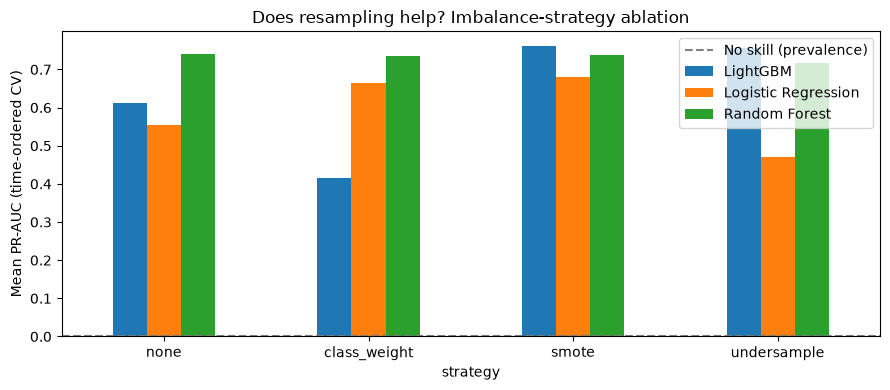


Imbalance strategy used from here on: 'smote'


In [21]:
ABLATE = {'lr': 'Logistic Regression', 'rf': 'Random Forest', 'lgbm': 'LightGBM'}      # drop 'rf' to save time
STRATEGIES = ['none', 'class_weight', 'smote', 'undersample']
cv_time = TimeSeriesSplit(n_splits=3)        # expanding window: train on the past, validate on the next block

rows, t0 = [], time.time()
for kind, label in ABLATE.items():
    for strategy in STRATEGIES:
        scores = cross_val_score(build_pipeline(kind, strategy), X_train, y_train,
                                 cv=cv_time, scoring='average_precision')
        rows.append({'model': label, 'strategy': strategy, 'mean_pr_auc': scores.mean(), 'std': scores.std()})
        print(f'{label:<20} {strategy:<13} PR-AUC {scores.mean():.4f} ± {scores.std():.4f}   ({time.time() - t0:.0f}s)')
ablation = pd.DataFrame(rows)

pivot = ablation.pivot(index='strategy', columns='model', values='mean_pr_auc').loc[STRATEGIES]
display(pivot.round(4))

ax = pivot.plot(kind='bar', figsize=(9, 4), rot=0)
ax.axhline(y_train.mean(), color='gray', linestyle='--', label='No skill (prevalence)')
ax.set_ylabel('Mean PR-AUC (time-ordered CV)')
ax.set_title('Does resampling help? Imbalance-strategy ablation')
ax.legend()
plt.tight_layout()
plt.show()

IMBALANCE = ablation.groupby('strategy')['mean_pr_auc'].mean().idxmax()
# IMBALANCE = 'class_weight'       # <- uncomment to override the automatic choice
print(f"\nImbalance strategy used from here on: '{IMBALANCE}'")

## 7. Model Comparison and Tuning

### 7.1 Candidates and baselines
All candidates are trained on the OOT **train** block and scored on the OOT **validation** block. The test block stays untouched.

- **Logistic Regression, Random Forest, XGBoost, LightGBM** each use the imbalance strategy selected in section 6, so the comparison is fair.
- **Dummy classifier** (always predicts the class prior): the no-skill reference. Its PR-AUC equals the fraud prevalence (~0.0017), which puts a PR-AUC like 0.80 in context.
- **Isolation Forest**: an unsupervised anomaly detector fitted without labels. If a supervised model barely beats it, the labels are adding little.

The earlier cross-validation on a random split is replaced by this time-ordered validation, because random CV can leak the future into the training folds.

In [22]:
KIND = {'Logistic Regression': 'lr', 'Random Forest': 'rf', 'XGBoost': 'xgb', 'LightGBM': 'lgbm'}

fitted, val_scores = {}, {}
for name, kind in KIND.items():
    t0 = time.time()
    pipe = build_pipeline(kind, IMBALANCE).fit(X_train, y_train)
    fitted[name] = pipe
    val_scores[name] = pipe.predict_proba(X_val)[:, 1]
    print(f'{name:<20} fitted in {time.time() - t0:5.1f}s')

# Baselines
dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)                 # no-skill reference
val_scores['Dummy (prior)'] = dummy.predict_proba(X_val)[:, 1]
iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train)      # unsupervised: labels never used
val_scores['Isolation Forest'] = -iso.score_samples(X_val)                      # higher = more anomalous


def rank_table(scores):
    t = pd.DataFrame({n: {'PR-AUC': average_precision_score(y_val, s), 'ROC-AUC': roc_auc_score(y_val, s)}
                      for n, s in scores.items()}).T
    return t.sort_values('PR-AUC', ascending=False)


ranking = rank_table(val_scores)
print(f'\nNo-skill PR-AUC on the validation block = fraud prevalence = {y_val.mean():.4f}')
display(ranking.round(4))

Logistic Regression  fitted in   1.0s
Random Forest        fitted in  32.3s
XGBoost              fitted in   6.0s
LightGBM             fitted in   4.3s

No-skill PR-AUC on the validation block = fraud prevalence = 0.0013


,PR-AUC,ROC-AUC
Random Forest,0.8435,0.9867
Logistic Regression,0.8428,0.9789
XGBoost,0.8024,0.9874
LightGBM,0.7000,0.9741
Isolation Forest,0.0343,0.9471
Dummy (prior),0.0013,0.5000


### 7.2 Hyper-parameter tuning

Everything so far uses near-default hyper-parameters. The best supervised model from the table above gets a small `RandomizedSearchCV`:
- scored on **average precision**, with **time-ordered** folds (`TimeSeriesSplit`)
- a deliberately small budget (`N_ITER`); raise it if you have the time

The tuned model competes with the untuned ones on the validation block, and the winner becomes the **final model**. With only a few dozen validation frauds, gaps of about 0.01 PR-AUC are noise, so prefer the simpler or faster model when results are that close.


In [23]:
tune_name = ranking.loc[list(KIND), 'PR-AUC'].idxmax()           # best supervised model on the validation block
tune_kind = KIND[tune_name]

param_dists = {
    'lr':   {'model__C': loguniform(1e-3, 1e2)},
    'rf':   {'model__n_estimators': [100, 200, 300], 'model__max_depth': [10, 20, None],
             'model__min_samples_leaf': [1, 2, 5], 'model__max_features': ['sqrt', 0.3]},
    'xgb':  {'model__n_estimators': [200, 400], 'model__max_depth': [3, 4, 6, 8],
             'model__learning_rate': [0.03, 0.05, 0.1], 'model__subsample': [0.7, 0.9],
             'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__min_child_weight': [1, 5]},
    'lgbm': {'model__n_estimators': [200, 400, 600], 'model__num_leaves': [15, 31, 63],
             'model__learning_rate': [0.02, 0.05, 0.1], 'model__min_child_samples': [10, 20, 50],
             'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__reg_lambda': [0, 1, 10]},
}
N_ITER = 8         # each iteration = 3 time-ordered CV fits; lower it if this is slow

search = RandomizedSearchCV(build_pipeline(tune_kind, IMBALANCE), param_dists[tune_kind], n_iter=N_ITER,
                            scoring='average_precision', cv=cv_time, random_state=RANDOM_STATE,
                            n_jobs=1, refit=True, verbose=1)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Tuned {tune_name} in {time.time() - t0:.0f}s | best CV PR-AUC {search.best_score_:.4f}')
print('Best params:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})

tuned_name = f'{tune_name} (tuned)'
fitted[tuned_name] = search.best_estimator_
val_scores[tuned_name] = search.best_estimator_.predict_proba(X_val)[:, 1]
ranking = rank_table(val_scores)
display(ranking.round(4))

# Final model = best supervised pipeline on the validation block
final_name = max(fitted, key=lambda name: ranking.loc[name, 'PR-AUC'])
final_pipe = fitted[final_name]
print(f'\nFinal model: {final_name}')

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuned Random Forest in 845s | best CV PR-AUC 0.7318
Best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


,PR-AUC,ROC-AUC
Random Forest,0.8435,0.9867
Logistic Regression,0.8428,0.9789
Random Forest (tuned),0.8412,0.9867
XGBoost,0.8024,0.9874
LightGBM,0.7000,0.9741
Isolation Forest,0.0343,0.9471
Dummy (prior),0.0013,0.5000



Final model: Random Forest


### 7.3 Precision-Recall curves of all models
The overlay below includes the no-skill line, so the gap between the models and chance is visible, and the unsupervised baseline for context.

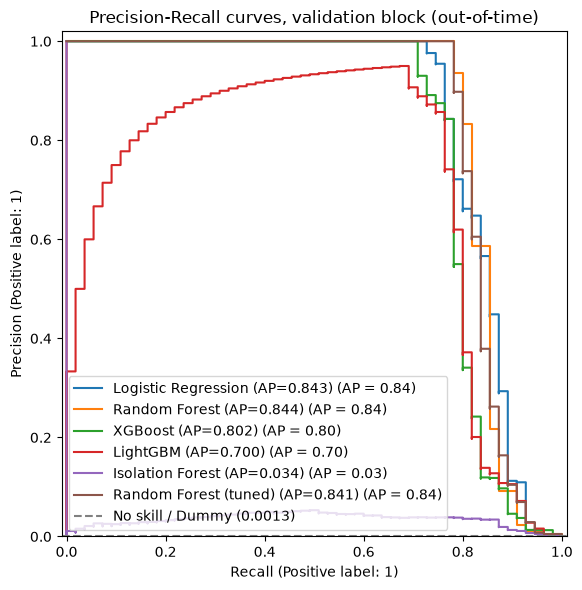

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, s in val_scores.items():
    if name == 'Dummy (prior)':
        continue                                                   # a flat line, drawn as "No skill" below
    PrecisionRecallDisplay.from_predictions(y_val, s, name=f'{name} (AP={average_precision_score(y_val, s):.3f})', ax=ax)
ax.axhline(y_val.mean(), color='gray', linestyle='--', label=f'No skill / Dummy ({y_val.mean():.4f})')
ax.set_title('Precision-Recall curves, validation block (out-of-time)')
ax.set_ylim(0, 1.02)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 8. Threshold Selection

By default `predict()` flags a transaction when its score is ≥ 0.5, but 0.5 has no special meaning for these models (and none at all for a model trained on resampled or re-weighted data).

The earlier argument was that a missed fraud costs far more than a false decline. Maximising **F1** does not reflect that, because F1 treats both errors symmetrically. Four rules are compared on the **validation** block:

| rule | idea |
|---|---|
| Default 0.5 | reference |
| Best F1 | symmetric trade-off between precision and recall |
| Best F2 | treats recall as twice as important as precision |
| **Minimum expected cost** | every alert costs `REVIEW_COST`; every *missed* fraud costs its actual `Amount` |

`REVIEW_COST` is an assumption (analyst time + customer friction), so a sensitivity table shows how the optimal threshold moves with it. The cost curve is also usually **flat** near the optimum, so treat the threshold as a range rather than a precise point. The chosen threshold is frozen here, and the test block is never used to adjust it.

,threshold,precision,recall,F1,alerts_per_10k,fraud_value_caught_%,expected_cost
Default 0.5,0.50,1.000,0.764,0.866,9.869,83.328,1609.83
Best F1,0.49,1.000,0.782,0.878,10.104,95.193,618.56
Best F2,0.38,0.936,0.800,0.863,11.043,95.220,636.34
Min expected cost (review=5),0.20,0.588,0.855,0.696,18.797,98.265,545.69


Expected cost with no model (nothing flagged): 8,396
Thresholds within 5% of the minimum cost span 0.20 to 0.20 (a wide range means the exact value is not critical)


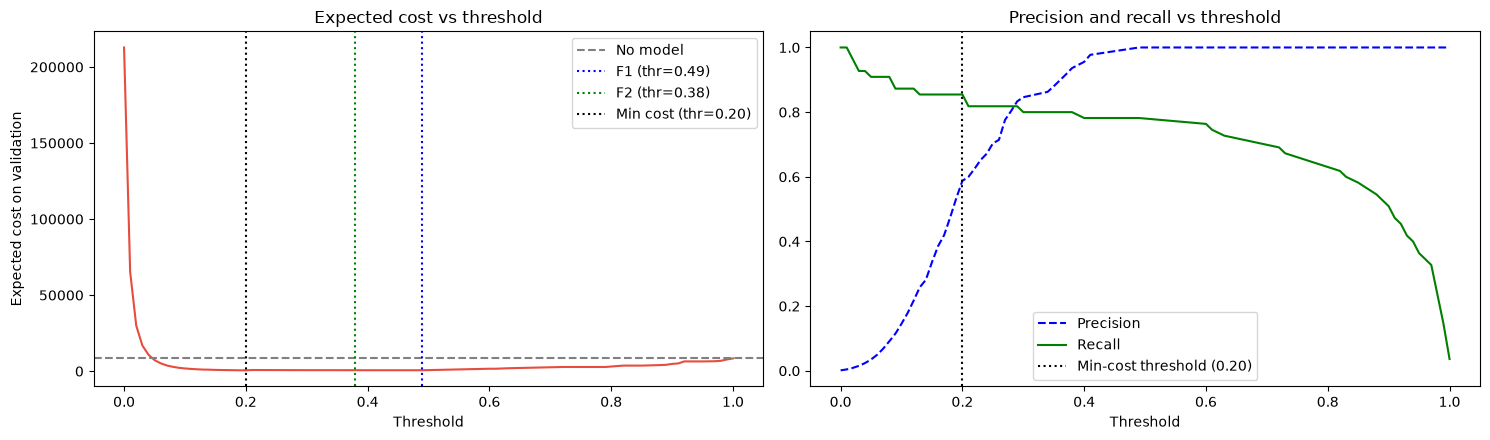

,best_threshold,recall,precision,alerts_per_10k
review_cost,,,,
1,0.20,0.855,0.588,18.797
5,0.20,0.855,0.588,18.797
20,0.49,0.782,1.000,10.104
50,0.49,0.782,1.000,10.104
100,0.49,0.782,1.000,10.104



Chosen operating threshold: 0.200


In [25]:
final_val = val_scores[final_name]

# Candidate thresholds
thr_f1, _ = best_fbeta_threshold(y_val, final_val, beta=1)
thr_f2, _ = best_fbeta_threshold(y_val, final_val, beta=2)
thr_grid, cost = cost_curve(y_val, final_val, amt_val, REVIEW_COST)
thr_cost = float(thr_grid[np.argmin(cost)])
no_model_cost = float((amt_val * y_val.values).sum())                 # nothing flagged: every fraud is lost

rules = {'Default 0.5': 0.5, 'Best F1': thr_f1, 'Best F2': thr_f2,
         f'Min expected cost (review={REVIEW_COST:g})': thr_cost}
table = {}
for rule, thr in rules.items():
    r = evaluate(y_val, final_val, amt_val, thr)
    table[rule] = {'threshold': thr, 'precision': r['precision'], 'recall': r['recall'], 'F1': r['f1'],
                   'alerts_per_10k': r['alerts_per_10k'], 'fraud_value_caught_%': r['fraud_value_caught_%'],
                   'expected_cost': r['expected_cost']}
display(pd.DataFrame(table).T.round(3))
print(f'Expected cost with no model (nothing flagged): {no_model_cost:,.0f}')

near = thr_grid[cost <= cost.min() * 1.05]
print(f'Thresholds within 5% of the minimum cost span {near.min():.2f} to {near.max():.2f} '
      f'(a wide range means the exact value is not critical)')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(thr_grid, cost, color='#e74c3c')
ax[0].axhline(no_model_cost, color='gray', linestyle='--', label='No model')
for label, thr, color in [('F1', thr_f1, 'blue'), ('F2', thr_f2, 'green'), ('Min cost', thr_cost, 'black')]:
    ax[0].axvline(thr, color=color, linestyle=':', label=f'{label} (thr={thr:.2f})')
ax[0].set_xlabel('Threshold')
ax[0].set_ylabel('Expected cost on validation')
ax[0].set_title('Expected cost vs threshold')
ax[0].legend()

prec, rec, thr_pr = precision_recall_curve(y_val, final_val)
ax[1].plot(thr_pr, prec[:-1], 'b--', label='Precision')
ax[1].plot(thr_pr, rec[:-1], 'g-', label='Recall')
ax[1].axvline(thr_cost, color='black', linestyle=':', label=f'Min-cost threshold ({thr_cost:.2f})')
ax[1].set_xlabel('Threshold')
ax[1].set_title('Precision and recall vs threshold')
ax[1].legend()
plt.tight_layout()
plt.show()

# Sensitivity: how does the optimal threshold move with the assumed cost of a review?
sens = []
for rc in [1, 5, 20, 50, 100]:
    tg, c = cost_curve(y_val, final_val, amt_val, rc)
    t_opt = float(tg[np.argmin(c)])
    r = evaluate(y_val, final_val, amt_val, t_opt, review_cost=rc)
    sens.append({'review_cost': rc, 'best_threshold': t_opt, 'recall': r['recall'],
                 'precision': r['precision'], 'alerts_per_10k': r['alerts_per_10k']})
display(pd.DataFrame(sens).set_index('review_cost').round(3))

thr_final = thr_cost        # operating point used on the test block. It is fixed from here on.
print(f'\nChosen operating threshold: {thr_final:.3f}')

## 9. Test Set Evaluation (out-of-time)

The final pipeline and the frozen threshold from section 8 are applied **once** to the test block (the most recent 15 % of transactions). Reported:

1. **Classification report and a labelled confusion matrix** (rows = actual, columns = predicted; scikit-learn's layout is `[[TN, FP], [FN, TP]]`).
2. **Value-based metrics.** Share of fraud *value* (not just count) caught, recall for a fixed **alert budget** ("analysts can review the top 0.1 % riskiest transactions"), and MCC, which stays informative under heavy imbalance.
3. **Bootstrap 95 % confidence intervals.** The test block contains only a few dozen frauds, so every single number here is uncertain. Read the intervals, not just the point estimates.

In [26]:
final_test = final_pipe.predict_proba(X_test)[:, 1]
y_t = y_test.values
res = evaluate(y_t, final_test, amt_test, thr_final)
pred_test = (final_test >= thr_final).astype(int)

print(f'Final model: {final_name} | threshold {thr_final:.3f} | '
      f'test block: {len(y_t):,} transactions, {int(y_t.sum())} frauds\n')
print(classification_report(y_t, pred_test, target_names=['Legit', 'Fraud'], digits=3))

# Confusion matrix with the correct layout: rows = actual, columns = predicted
cm_df = pd.DataFrame([[res['tn'], res['fp']], [res['fn'], res['tp']]],
                     index=['Actual: Legit', 'Actual: Fraud'], columns=['Pred: Legit', 'Pred: Fraud'])
display(cm_df)

# Alert-budget view: "if analysts can only review the top X % riskiest transactions..."
display(pd.DataFrame([recall_at_budget(y_t, final_test, amt_test, f) for f in [0.0005, 0.001, 0.002, 0.005]])
        .set_index('budget').round(3))

# Bootstrap 95% confidence intervals (resample test transactions with replacement; the threshold stays fixed)
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_STATE)
boot_rows = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_t), len(y_t))
    boot_rows.append(evaluate(y_t[idx], final_test[idx], amt_test[idx], thr_final))
boot = pd.DataFrame(boot_rows)

metrics = ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1', 'mcc', 'fraud_value_caught_%']
ci = pd.DataFrame({'estimate': pd.Series(res)[metrics].astype(float),
                   'ci_low': boot[metrics].quantile(0.025),
                   'ci_high': boot[metrics].quantile(0.975)})
display(ci.round(3))
print(f'Only {int(y_t.sum())} frauds in the test block, so the intervals are wide: read single numbers with care.')

Final model: Random Forest | threshold 0.200 | test block: 42,559 transactions, 52 frauds

              precision    recall  f1-score   support

       Legit      1.000     0.999     0.999     42507
       Fraud      0.500     0.769     0.606        52

    accuracy                          0.999     42559
   macro avg      0.750     0.884     0.803     42559
weighted avg      0.999     0.999     0.999     42559



,Pred: Legit,Pred: Fraud
Actual: Legit,42467,40
Actual: Fraud,12,40


,alerts,precision,recall,fraud_value_caught_%
budget,,,,
top 0.05%,21,1.000,0.404,35.808
top 0.10%,43,0.884,0.731,57.525
top 0.20%,85,0.471,0.769,71.825
top 0.50%,213,0.202,0.827,77.941


,estimate,ci_low,ci_high
pr_auc,0.777,0.653,0.882
roc_auc,0.962,0.924,0.993
precision,0.500,0.390,0.606
recall,0.769,0.641,0.881
f1,0.606,0.500,0.697
mcc,0.620,0.516,0.707
fraud_value_caught_%,71.825,35.822,97.756


Only 52 frauds in the test block, so the intervals are wide: read single numbers with care.


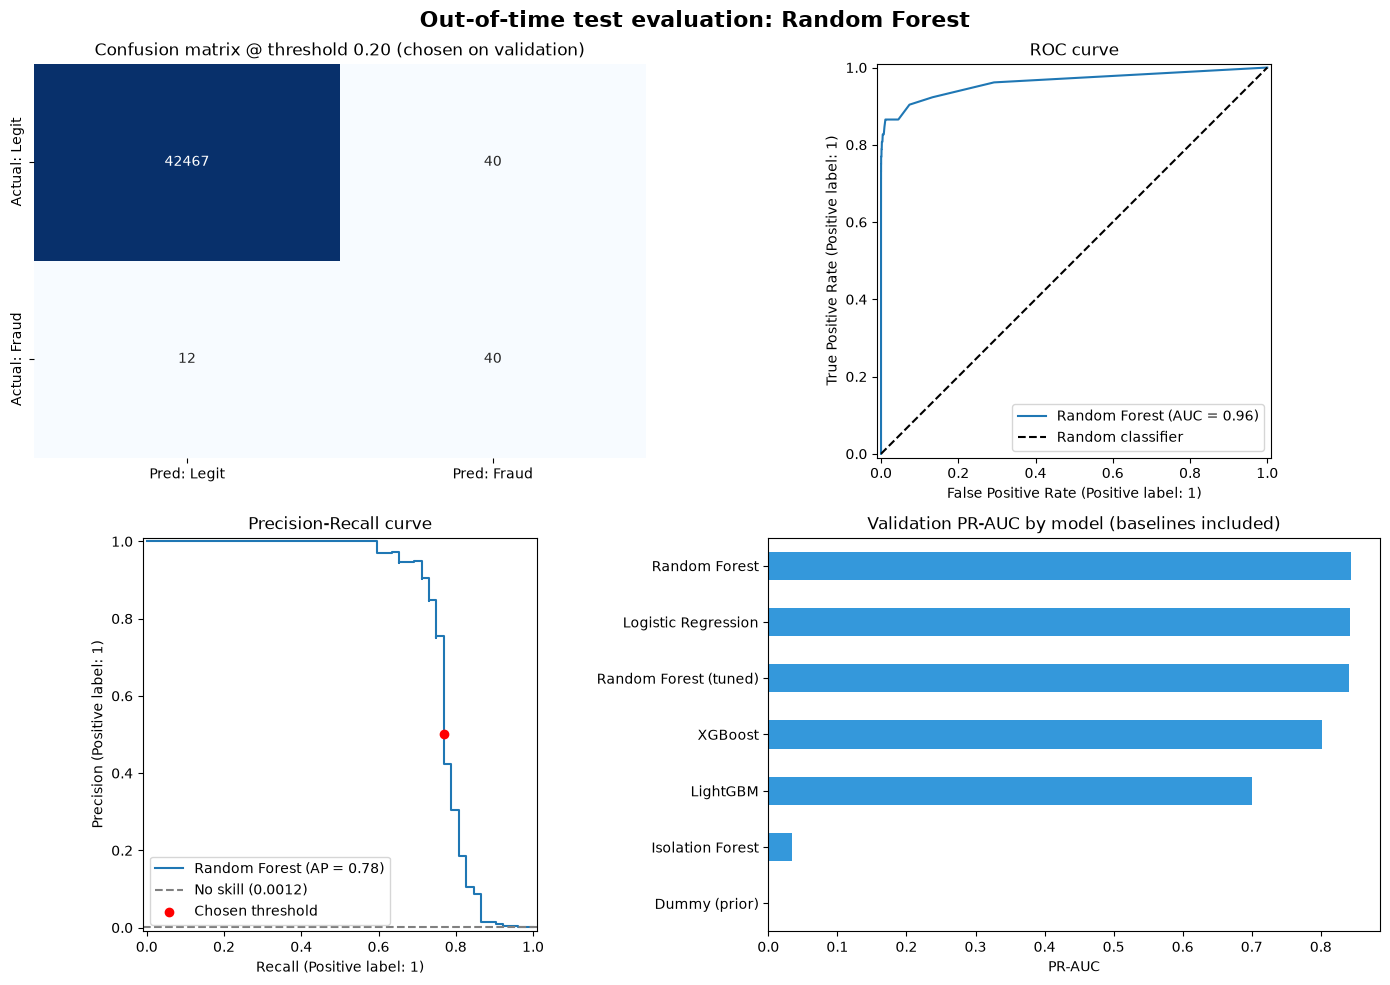

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Out-of-time test evaluation: {final_name}', fontsize=16, fontweight='bold')

sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0, 0])
axes[0, 0].set_title(f'Confusion matrix @ threshold {thr_final:.2f} (chosen on validation)')

RocCurveDisplay.from_predictions(y_t, final_test, name=final_name, ax=axes[0, 1])
axes[0, 1].plot([0, 1], [0, 1], 'k--', label='Random classifier')
axes[0, 1].set_title('ROC curve')
axes[0, 1].legend()

PrecisionRecallDisplay.from_predictions(y_t, final_test, name=final_name, ax=axes[1, 0])
axes[1, 0].axhline(y_t.mean(), color='gray', linestyle='--', label=f'No skill ({y_t.mean():.4f})')
axes[1, 0].scatter([res['recall']], [res['precision']], color='red', zorder=5, label='Chosen threshold')
axes[1, 0].set_title('Precision-Recall curve')
axes[1, 0].legend(loc='lower left')

ranking['PR-AUC'].sort_values().plot(kind='barh', ax=axes[1, 1], color='#3498db')
axes[1, 1].set_title('Validation PR-AUC by model (baselines included)')
axes[1, 1].set_xlabel('PR-AUC')

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

### Reading the test results

- **ROC-AUC vs PR-AUC.** With ~0.17 % fraud, ROC-AUC looks excellent almost regardless of model quality, because the huge legit class keeps the false-positive *rate* tiny. PR-AUC, compared with the no-skill line at the prevalence, is the honest summary.
- **Precision and recall at the chosen threshold** describe the operating point, not the model's ranking quality. Compare them with the alert-budget table: both answer "how many frauds do we catch for how many alerts?".
- **Confidence intervals.** If the interval of a metric is wide, differences between models, or between protocols, smaller than that width are not evidence of anything.

### Random split vs out-of-time split
The table below trains the same final pipeline on a stratified random 80/20 split of all transactions and applies the same threshold, next to the out-of-time result. A random split lets the model see the future, so it tends to be optimistic. Check the gap, and remember that it is noisy with this few frauds.

In [28]:
# Same final pipeline configuration, trained and tested under two protocols, evaluated at the same threshold
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y_all)
rand_pipe = clone(final_pipe).fit(Xr_tr, yr_tr)
rand_scores = rand_pipe.predict_proba(Xr_te)[:, 1]

protocol = pd.DataFrame({
    'Random stratified split (80/20)': evaluate(yr_te.values, rand_scores, amount_all.loc[yr_te.index].values, thr_final),
    'Out-of-time split (last 15%)': res,
}).T[['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'fraud_value_caught_%']]
protocol.insert(0, 'test_frauds', [int(yr_te.sum()), int(y_t.sum())])
display(protocol.round(3))

,test_frauds,roc_auc,pr_auc,precision,recall,f1,fraud_value_caught_%
Random stratified split (80/20),95,0.965,0.800,0.726,0.811,0.766,74.382
Out-of-time split (last 15%),52,0.962,0.777,0.500,0.769,0.606,71.825


## 10. Probability Calibration

A model trained on SMOTE-resampled or class-weighted data outputs scores that are **not** probabilities. They behave as if fraud were as common as legit transactions, not 0.17 %, so a score of 0.9 does not mean "90 % chance of fraud".

That does not matter for ranking, or for the threshold above (which was tuned on the same raw scores). It does matter if the score is shown to analysts or used in expected-loss calculations. **Platt scaling** (a one-feature logistic regression on the logit of the score, fitted on the **validation** block only) maps scores to calibrated probabilities. Because the mapping is monotonic, **PR-AUC and ROC-AUC do not change**, and the table at the end of the next cell confirms it.

How to read the reliability tables: within each score bin, does the *mean predicted* probability match the *observed* fraud rate? The Brier score summarises the overall gap (lower is better; the last row is a model that always predicts the prevalence).

Raw model score:


,n,frauds,mean_predicted,observed_rate
bin,,,,
"[0.0, 0.001)",30074,2,0.00000,0.00007
"[0.005, 0.02)",6769,2,0.01000,0.00030
"[0.02, 0.1)",5370,5,0.03220,0.00093
"[0.1, 0.3)",293,3,0.13703,0.01024
"[0.3, 0.6)",14,3,0.39357,0.21429
"[0.6, 1.0)",39,37,0.92128,0.94872


After Platt scaling:


,n,frauds,mean_predicted,observed_rate
bin,,,,
"[0.0, 0.001)",40608,7,0.00006,0.00017
"[0.001, 0.005)",1428,0,0.00213,0.00000
"[0.005, 0.02)",385,3,0.00970,0.00779
"[0.02, 0.1)",82,2,0.03761,0.02439
"[0.1, 0.3)",15,3,0.18196,0.20000
"[0.3, 0.6)",2,0,0.43475,0.00000
"[0.6, 1.0)",39,37,0.96884,0.94872


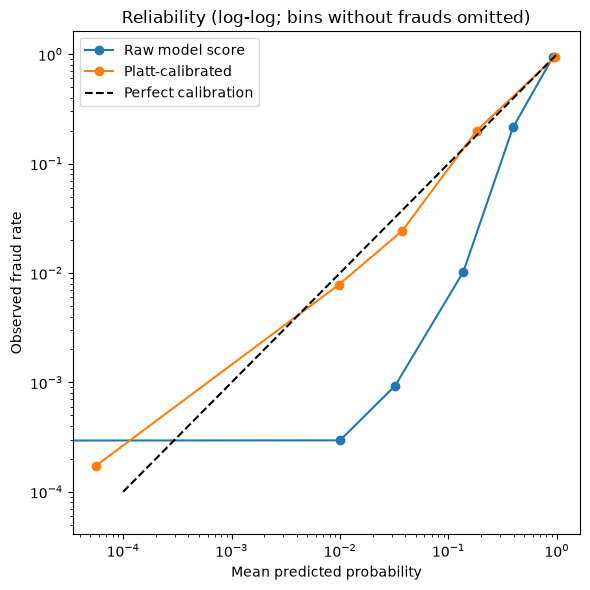

,Brier score,PR-AUC
Raw score,0.00068,0.77718
Platt-calibrated,0.00039,0.77718
Constant prevalence (baseline),0.00122,NaN


In [29]:
def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


# Platt scaling fitted on the validation block only
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(final_val).reshape(-1, 1), y_val)
cal_test = platt.predict_proba(logit(final_test).reshape(-1, 1))[:, 1]

edges = [0, 0.001, 0.005, 0.02, 0.1, 0.3, 0.6, 1.0001]


def reliability(y, p):
    t = pd.DataFrame({'p': p, 'y': y})
    t['bin'] = pd.cut(t['p'], edges, right=False)
    g = t.groupby('bin', observed=True).agg(n=('y', 'size'), frauds=('y', 'sum'), mean_predicted=('p', 'mean'))
    g['observed_rate'] = g['frauds'] / g['n']
    return g


print('Raw model score:')
display(reliability(y_t, final_test).round(5))
print('After Platt scaling:')
display(reliability(y_t, cal_test).round(5))

fig, ax = plt.subplots(figsize=(6, 6))
for label, p in [('Raw model score', final_test), ('Platt-calibrated', cal_test)]:
    g = reliability(y_t, p)
    g = g[g['frauds'] > 0]                                          # zero-fraud bins cannot be drawn on a log axis
    ax.plot(g['mean_predicted'], g['observed_rate'], 'o-', label=label)
ax.plot([1e-4, 1], [1e-4, 1], 'k--', label='Perfect calibration')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed fraud rate')
ax.set_title('Reliability (log-log; bins without frauds omitted)')
ax.legend()
plt.tight_layout()
plt.show()

brier_baseline = brier_score_loss(y_t, np.full(len(y_t), y_t.mean()))
display(pd.DataFrame({
    'Brier score': [brier_score_loss(y_t, final_test), brier_score_loss(y_t, cal_test), brier_baseline],
    'PR-AUC': [average_precision_score(y_t, final_test), average_precision_score(y_t, cal_test), np.nan],
}, index=['Raw score', 'Platt-calibrated', 'Constant prevalence (baseline)']).round(5))

## 11. Error Analysis

Aggregate metrics hide *which* transactions the model gets wrong. Questions to ask of the cells below:

- **Missed frauds (false negatives):** are they small amounts (cheap misses) or large ones (costly)? Do they score *close to* the threshold (a threshold or cost-setting issue) or *near zero* (the model sees no signal at all, so it needs new features or data)?
- **False alarms (false positives):** what do they have in common (amount, hour, score)? Are there a few very high-scoring look-alikes, or a diffuse crowd just above the threshold?
- **Caught vs missed frauds:** do the two groups differ in amount or hour?

The next section (SHAP) draws waterfall plots for individual caught and missed frauds to show *why* the model scored them as it did.

Caution: this is the test block. Use it to understand the model, not to tune it. If you change the model after looking, evaluate on fresh data (a later time period) before trusting the new numbers.

Caught frauds (TP): 40 | Missed frauds (FN): 12 | False alarms (FP): 40

Missed frauds (lowest score first):


,hour,Amount,score
253455,19.531,7.59,0.00
275040,22.356,19.95,0.00
253404,19.524,187.11,0.01
244437,18.419,2.47,0.01
273358,22.106,0.00,0.02
280611,23.319,42.53,0.03
248322,18.864,1096.99,0.03
250958,19.206,3.14,0.08
262115,20.664,1.00,0.09
250968,19.208,7.06,0.12


False alarms (highest score first, top 25):


,hour,Amount,score
273442,22.118,2.00,0.85
262008,20.650,451.81,0.77
281243,23.447,333.77,0.56
267910,21.402,239.88,0.47
276728,22.624,1.99,0.43
248760,18.924,606.90,0.42
276693,22.618,1.00,0.41
276833,22.642,1.99,0.37
247664,18.779,1.00,0.36
249280,18.994,261.58,0.35


Median amount and score by group:


,caught frauds,missed frauds,false alarms,all legit
Amount,4.795,9.95,26.45,16.01
score,0.950,0.03,0.27,0.00


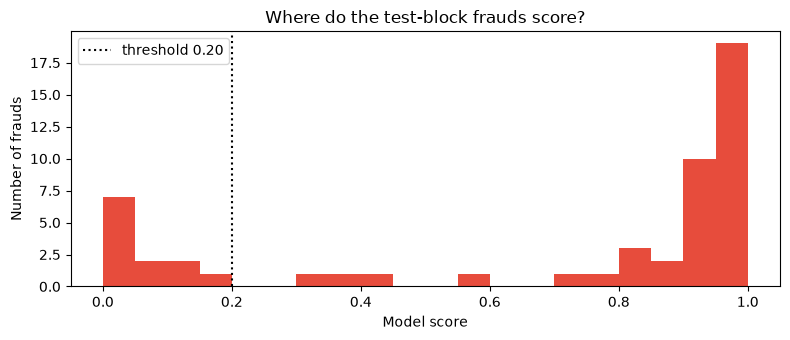

In [30]:
err = X_test.copy()
err['Class'] = y_t
err['score'] = final_test
err['Amount'] = amt_test
err['hour'] = (raw_test['Time'].values % 86400) / 3600             # hour of day, relative to the start of the data
err['pred'] = (final_test >= thr_final).astype(int)

tp_df = err[(err['Class'] == 1) & (err['pred'] == 1)].sort_values('score', ascending=False)
fn_df = err[(err['Class'] == 1) & (err['pred'] == 0)].sort_values('score')
fp_df = err[(err['Class'] == 0) & (err['pred'] == 1)].sort_values('score', ascending=False)
print(f'Caught frauds (TP): {len(tp_df)} | Missed frauds (FN): {len(fn_df)} | False alarms (FP): {len(fp_df)}')

cols = ['hour', 'Amount', 'score']
print('\nMissed frauds (lowest score first):')
display(fn_df[cols].round(3))
print('False alarms (highest score first, top 25):')
display(fp_df[cols].head(25).round(3))

print('Median amount and score by group:')
display(pd.DataFrame({
    'caught frauds': tp_df[['Amount', 'score']].median(),
    'missed frauds': fn_df[['Amount', 'score']].median(),
    'false alarms': fp_df[['Amount', 'score']].median(),
    'all legit': err.loc[err['Class'] == 0, ['Amount', 'score']].median(),
}).round(3))

plt.figure(figsize=(8, 3.5))
plt.hist(err.loc[err['Class'] == 1, 'score'], bins=20, color='#e74c3c')
plt.axvline(thr_final, color='black', linestyle=':', label=f'threshold {thr_final:.2f}')
plt.xlabel('Model score')
plt.ylabel('Number of frauds')
plt.title('Where do the test-block frauds score?')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Explainability (SHAP)

Black-box models are heavily regulated in finance, so it matters *why* a transaction was flagged. Design choices:

- **A usable sample.** A random sample of 1,000 test rows contains only about one fraud (the fraud rate is ~0.1 %), so its plot would mostly show what makes *legit* transactions look legit. Instead the sample is **all test frauds plus 500 random legit transactions**, and a second plot shows **frauds only**.
- **Local explanations.** Waterfall plots for individual caught and missed frauds: the per-transaction "why" that regulators and analysts actually ask for.
- **A cross-check.** Permutation importance (the drop in validation PR-AUC when a feature is shuffled) is compared with mean |SHAP|. Agreement between two different methods is stronger evidence than either alone.

Units: SHAP values are in probability units for Random Forest (and for the model-agnostic fallback used if a non-tree model wins) and in log-odds for XGBoost/LightGBM. Features are shown in their original units.

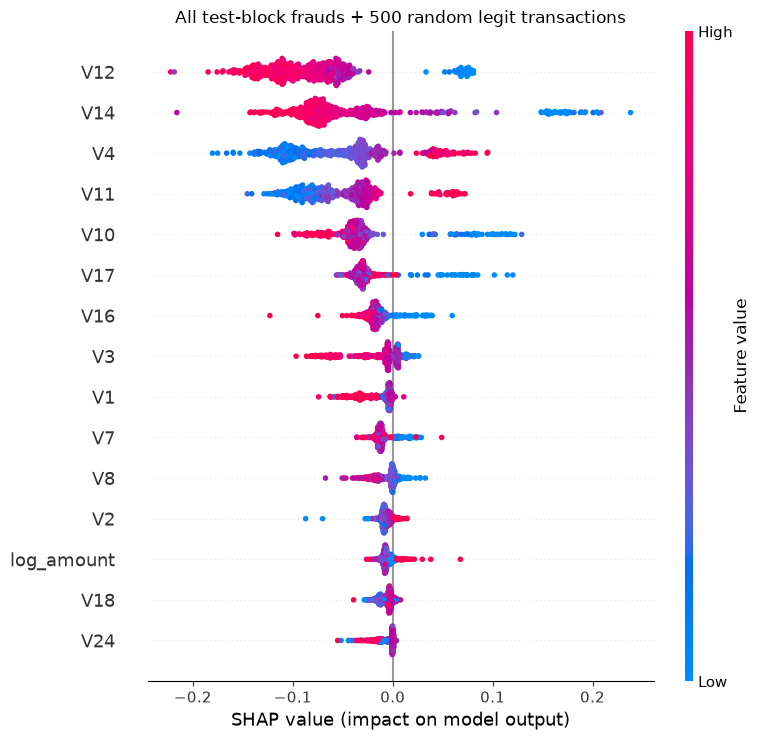

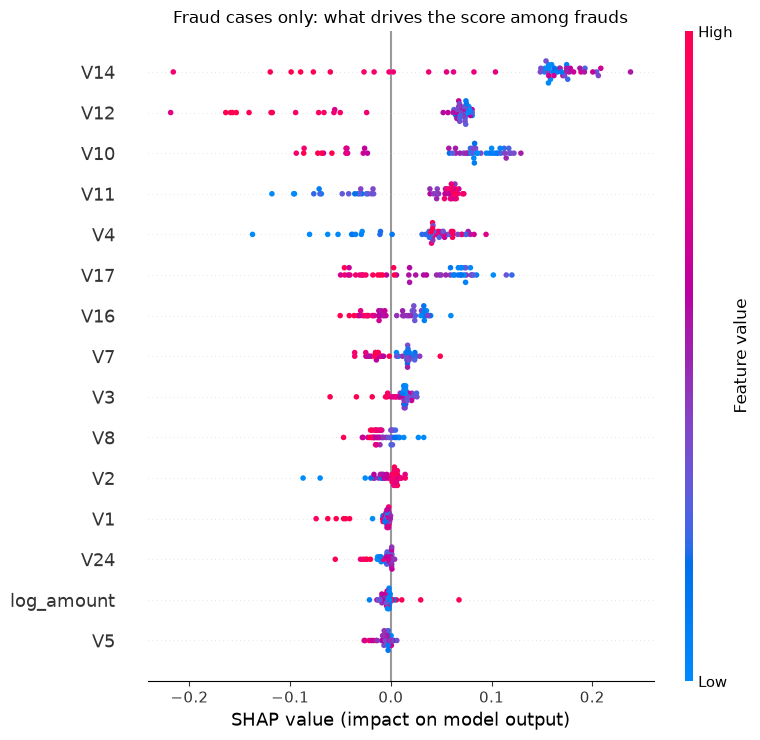

Top drivers on this sample (auto-generated):

- **V12**: mean |SHAP| 0.0913; lower values push the fraud score up (corr(value, SHAP) = -0.87)
- **V14**: mean |SHAP| 0.0744; lower values push the fraud score up (corr(value, SHAP) = -0.89)
- **V4**: mean |SHAP| 0.0650; higher values push the fraud score up (corr(value, SHAP) = +0.85)
- **V11**: mean |SHAP| 0.0605; higher values push the fraud score up (corr(value, SHAP) = +0.93)
- **V10**: mean |SHAP| 0.0454; lower values push the fraud score up (corr(value, SHAP) = -0.80)
- **V17**: mean |SHAP| 0.0325; lower values push the fraud score up (corr(value, SHAP) = -0.71)

In [31]:
final_model = final_pipe.named_steps['model']

# Sample: ALL test frauds + 500 random legit transactions (a random sample of the test block contains almost no frauds)
rng = np.random.default_rng(RANDOM_STATE)
fraud_pos = np.flatnonzero(y_t == 1)
legit_pos = rng.choice(np.flatnonzero(y_t == 0), size=min(500, int((y_t == 0).sum())), replace=False)
sample_pos = np.sort(np.r_[fraud_pos, legit_pos])
X_shap = X_test.iloc[sample_pos]
is_fraud_row = y_t[sample_pos] == 1

if isinstance(final_model, (RandomForestClassifier, XGBClassifier, LGBMClassifier)):
    explainer = shap.TreeExplainer(final_model)

    def fraud_explanation(X):
        """SHAP values for the 'fraud' class only (RF returns one block per class, boosting models one)."""
        ex = explainer(X, check_additivity=False)
        return ex[:, :, 1] if ex.values.ndim == 3 else ex
else:
    # Not a tree model (e.g. logistic regression): model-agnostic explainer on the pipeline's fraud probability (slower)
    background = shap.sample(X_train, 100, random_state=RANDOM_STATE)
    explainer = shap.Explainer(lambda d: final_pipe.predict_proba(pd.DataFrame(d, columns=X_train.columns))[:, 1],
                               background)

    def fraud_explanation(X):
        return explainer(X)


sv = fraud_explanation(X_shap)

for title, mask in [('All test-block frauds + 500 random legit transactions', np.ones(len(X_shap), dtype=bool)),
                    ('Fraud cases only: what drives the score among frauds', is_fraud_row)]:
    shap.summary_plot(sv.values[mask], X_shap[mask], max_display=15, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Auto-generated reading of the top drivers (so the text always matches the plot)
shap_imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
bullets = []
for f in shap_imp.index[:6]:
    r = np.corrcoef(X_shap[f].values, sv.values[:, X_shap.columns.get_loc(f)])[0, 1]
    effect = ('higher values push the fraud score up' if r > 0.2 else
              'lower values push the fraud score up' if r < -0.2 else 'mixed / non-monotonic effect')
    bullets.append(f'- **{f}**: mean |SHAP| {shap_imp[f]:.4f}; {effect} (corr(value, SHAP) = {r:+.2f})')
display(Markdown('Top drivers on this sample (auto-generated):\n\n' + '\n'.join(bullets)))

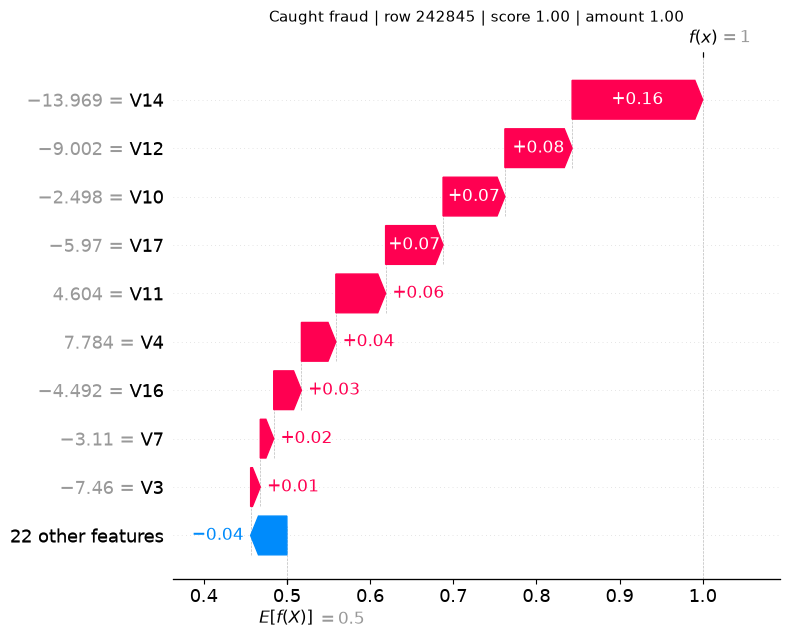

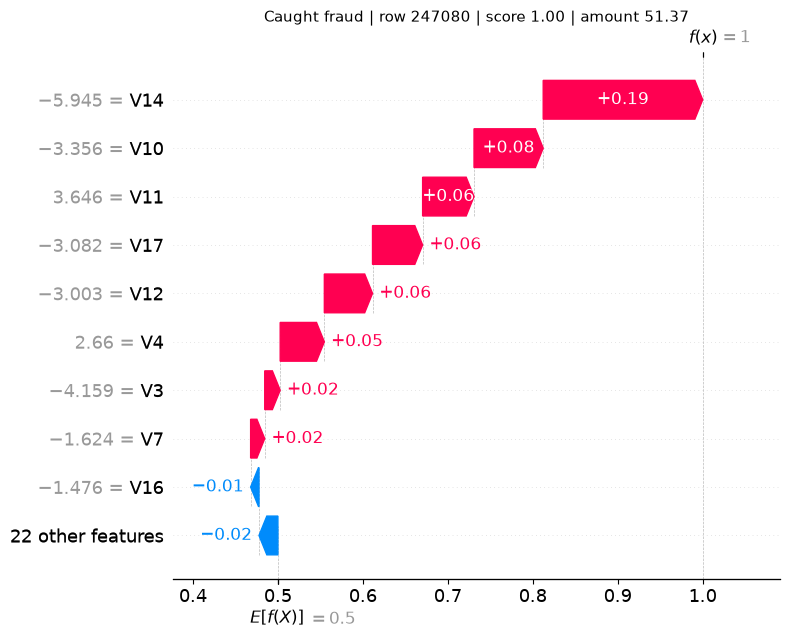

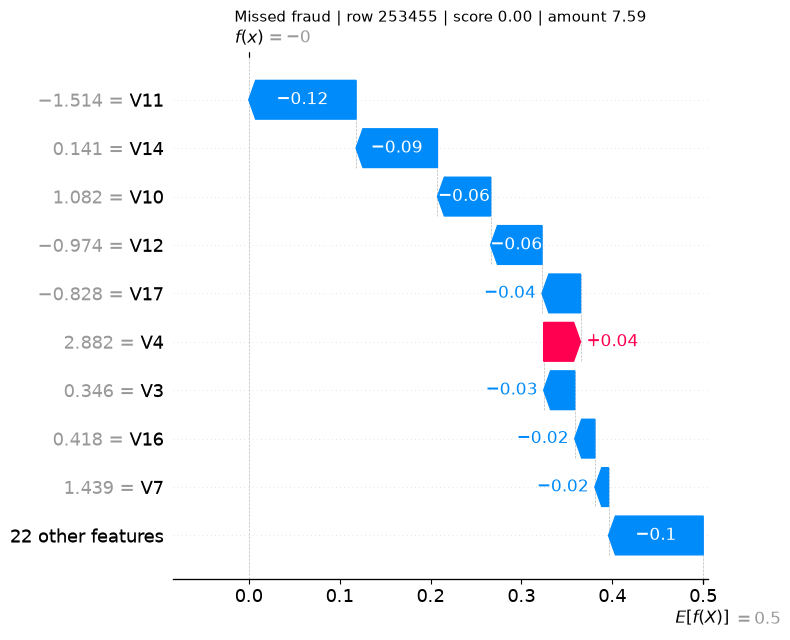

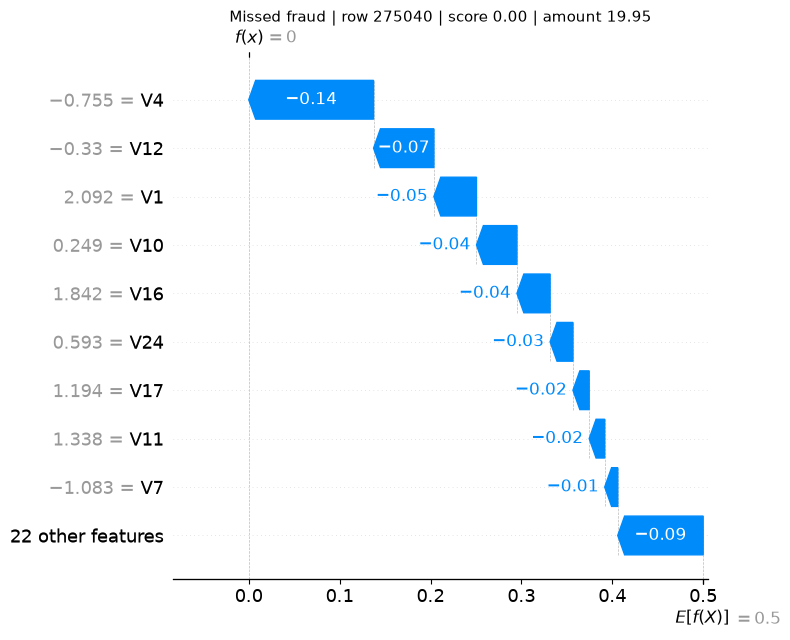

In [32]:
def waterfall_for(row_label, title):
    ex = fraud_explanation(X_test.loc[[row_label]])
    shap.plots.waterfall(ex[0], max_display=10, show=False)
    plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()


for group, d in [('Caught fraud', tp_df.head(2)), ('Missed fraud', fn_df.head(2))]:
    for row_label, row in d.iterrows():
        waterfall_for(row_label, f"{group} | row {row_label} | score {row['score']:.2f} | amount {row['Amount']:.2f}")

In [33]:
perm = permutation_importance(final_pipe, X_val, y_val, scoring='average_precision',
                              n_repeats=3, random_state=RANDOM_STATE)
imp = pd.DataFrame({
    'mean_abs_SHAP': shap_imp,
    'perm_importance_PR-AUC_drop': pd.Series(perm.importances_mean, index=X_val.columns),
})
imp['SHAP_rank'] = imp['mean_abs_SHAP'].rank(ascending=False)
imp['perm_rank'] = imp['perm_importance_PR-AUC_drop'].rank(ascending=False)
display(imp.sort_values('SHAP_rank').head(12).round(4))
print('Spearman rank correlation between the two importance measures:',
      round(imp['SHAP_rank'].corr(imp['perm_rank'], method='spearman'), 3))

,mean_abs_SHAP,perm_importance_PR-AUC_drop,SHAP_rank,perm_rank
V12,0.0913,0.1266,1.0,1.0
V14,0.0744,0.0618,2.0,2.0
V4,0.0650,0.0606,3.0,3.0
V11,0.0605,0.0484,4.0,4.0
V10,0.0454,0.0071,5.0,12.0
V17,0.0325,-0.0011,6.0,29.0
V16,0.0183,0.0049,7.0,14.0
V3,0.0177,0.0084,8.0,9.0
V1,0.0153,0.0141,9.0,5.0
V7,0.0130,-0.0001,10.0,28.0


Spearman rank correlation between the two importance measures: 0.348


### How to read these plots (and what it does not claim)

- **Global plot (beeswarm):** features are ranked by mean |SHAP|. Each dot is a transaction, its colour is the feature value, and its position is the push on the fraud score. For each top feature, say whether high or low values push the score up (the auto-generated list above does this).
- **Frauds-only plot:** shows what separates strongly flagged frauds from weakly flagged ones, which the mixed plot hides.
- **Waterfalls:** start from the average model output and add each feature's contribution to reach this transaction's score. For a *missed* fraud, look for the features that pulled the score down. They show what the model considers "normal" about it.
- **Permutation importance** answers a different question (how much does performance drop without the feature?). A feature that ranks high on both measures is a robust driver. Large disagreements usually mean correlated features, or noise from the small number of validation frauds.

Wording to avoid:
- *"X is the strongest indicator of fraud."* SHAP shows what the **model relies on**, not what causes fraud.
- *Claims about combinations of features* ("high V4 together with low V12"). The summary plot shows single-feature effects only. Supporting a claim about interactions needs SHAP dependence or interaction plots.
- *Business meanings for V1–V28.* They are PCA components of undisclosed features, so only their direction and size can be described.
- The mean |SHAP| ranking comes from a *sample* (all frauds + 500 legit), not from the natural class mix.

## 13. Saving the Model

The final pipeline, the frozen threshold, the Platt calibrator and the feature list are saved together, **after** every fitting decision is made. (Saving earlier would store a stale model without the threshold it needs.)

To score new data, pass the raw columns (`Time`, `V1`–`V28`, `Amount`) to `score_transactions()` below. It calls `make_features()` itself. The cell reloads the file and checks that it reproduces the in-memory predictions exactly.

Note for apps: the saved object is a dictionary (pipeline, threshold, calibrator, feature list), and the model expects the engineered features. An app that loads a plain pipeline, such as the old `fraud_pipeline.joblib`, must be updated to load the bundle, call `make_features()` and use the saved threshold.

In [34]:
bundle = {
    'pipeline': final_pipe,
    'threshold': float(thr_final),
    'calibrator': platt,                       # Platt scaling on logit(score); apply logit() to the raw score first
    'features': list(X_train.columns),
    'model_name': final_name,
    'imbalance_strategy': IMBALANCE,
    'review_cost_assumption': REVIEW_COST,
    'trained_on': 'first 70% of transactions by Time (out-of-time split)',
}
joblib.dump(bundle, 'fraud_model_bundle.joblib')


def score_transactions(raw: pd.DataFrame, path='fraud_model_bundle.joblib') -> pd.DataFrame:
    """Raw columns (Time, V1..V28, Amount) -> raw score, calibrated probability, flag. Needs make_features() and logit()."""
    b = joblib.load(path)
    score = b['pipeline'].predict_proba(make_features(raw)[b['features']])[:, 1]
    prob = b['calibrator'].predict_proba(logit(score).reshape(-1, 1))[:, 1]
    return pd.DataFrame({'fraud_score': score, 'fraud_probability': prob,
                         'flag': (score >= b['threshold']).astype(int)}, index=raw.index)


# Round-trip check: the reloaded bundle must reproduce the in-memory predictions exactly
check = score_transactions(raw_test.head(500))
assert np.allclose(check['fraud_score'], final_test[:500]), 'saved bundle does not match the in-memory model'
assert np.allclose(check['fraud_probability'], cal_test[:500]), 'saved calibrator does not match'
print('Saved fraud_model_bundle.joblib and verified that it reproduces the in-memory predictions.')

Saved fraud_model_bundle.joblib and verified that it reproduces the in-memory predictions.


In [35]:
# Getting sample.csv (raw columns, for demos). These rows come from the whole dataset, so many were seen in training.
sample = pd.concat([
    df[df['Class'] == 0].sample(15, random_state=42),
    df[df['Class'] == 1].sample(5, random_state=42),
])
sample.to_csv('sample.csv', index=False)

demo = pd.read_csv('sample.csv')
display(score_transactions(demo).assign(actual=demo['Class']).round(4))

,fraud_score,fraud_probability,flag,actual
0,0.00,0.0000,0,0
1,0.00,0.0000,0,0
2,0.00,0.0000,0,0
3,0.00,0.0000,0,0
4,0.00,0.0000,0,0
5,0.00,0.0000,0,0
6,0.00,0.0000,0,0
7,0.00,0.0000,0,0
8,0.00,0.0000,0,0
9,0.00,0.0000,0,0


In [36]:
oot_row = protocol.loc['Out-of-time split (last 15%)']
rnd_row = protocol.loc['Random stratified split (80/20)']


def ci_txt(metric, pct=False):
    e, lo, hi = ci.loc[metric, ['estimate', 'ci_low', 'ci_high']]
    return f'{e:.1f} % ({lo:.1f} to {hi:.1f})' if pct else f'{e:.3f} ({lo:.3f} to {hi:.3f})'


total_fraud_value = float((amt_test * y_t).sum())
cost_saving = 100 * (1 - res['expected_cost'] / total_fraud_value)
top5 = ', '.join(shap_imp.index[:5])
pr_txt, roc_txt = ci_txt('pr_auc'), ci_txt('roc_auc')
prec_txt, rec_txt, mcc_txt = ci_txt('precision'), ci_txt('recall'), ci_txt('mcc')
value_txt = ci_txt('fraud_value_caught_%', pct=True)
fa_txt = f"{res['fp']} false alarm" + ('' if res['fp'] == 1 else 's')

display(Markdown(f"""
### Final results (generated from the cells above, so they always match the outputs)

- **Model:** {final_name} · imbalance handling: `{IMBALANCE}` · trained on the first 70 % of transactions by time
- **Operating threshold:** {thr_final:.3f}, fixed on the validation block by minimising expected cost (review cost {REVIEW_COST:g} per alert; a missed fraud costs its Amount)
- **Out-of-time test block:** {len(y_t):,} transactions, {int(y_t.sum())} frauds (estimate, 95 % bootstrap interval)
  - PR-AUC {pr_txt} · ROC-AUC {roc_txt}
  - Precision {prec_txt} · Recall {rec_txt} · MCC {mcc_txt}
  - {res['tp']} of {res['tp'] + res['fn']} frauds caught, {res['fn']} missed, {fa_txt} ({res['alerts_per_10k']:.1f} alerts per 10,000 transactions)
  - Fraud value caught: {value_txt}; expected cost is {cost_saving:.0f} % lower than flagging nothing
- **Random vs out-of-time split:** PR-AUC {rnd_row['pr_auc']:.3f} vs {oot_row['pr_auc']:.3f}; ROC-AUC {rnd_row['roc_auc']:.3f} vs {oot_row['roc_auc']:.3f}
- **Features the model relies on most (mean |SHAP|):** {top5}
"""))


### Final results (generated from the cells above, so they always match the outputs)

- **Model:** Random Forest · imbalance handling: `smote` · trained on the first 70 % of transactions by time
- **Operating threshold:** 0.200, fixed on the validation block by minimising expected cost (review cost 5 per alert; a missed fraud costs its Amount)
- **Out-of-time test block:** 42,559 transactions, 52 frauds (estimate, 95 % bootstrap interval)
  - PR-AUC 0.777 (0.653 to 0.882) · ROC-AUC 0.962 (0.924 to 0.993)
  - Precision 0.500 (0.390 to 0.606) · Recall 0.769 (0.641 to 0.881) · MCC 0.620 (0.516 to 0.707)
  - 40 of 52 frauds caught, 12 missed, 40 false alarms (18.8 alerts per 10,000 transactions)
  - Fraud value caught: 71.8 % (35.8 to 97.8); expected cost is 65 % lower than flagging nothing
- **Random vs out-of-time split:** PR-AUC 0.800 vs 0.777; ROC-AUC 0.965 vs 0.962
- **Features the model relies on most (mean |SHAP|):** V12, V14, V4, V11, V10


## 14. Conclusion, Limitations and Next Steps

### What this notebook shows
- Fraud detection with a ~0.17 % positive rate was evaluated with **time-ordered** train / validation / test blocks, so the performance estimate mimics deployment instead of leaking the future into training.
- Imbalance handling was **compared, not assumed**: no resampling vs class weights vs SMOTE vs undersampling on identical time-ordered folds, with one fix per pipeline.
- Candidates, including a no-skill baseline and an unsupervised Isolation Forest, were compared on **PR-AUC**, the metric that is informative at this class ratio. The best was tuned and selected on validation data only.
- The operating threshold minimises an **expected cost that uses real transaction amounts**, and was frozen before the test block was touched.
- Test results come with **bootstrap confidence intervals**, value-based metrics (share of fraud value caught, recall at a fixed alert budget) and a side-by-side comparison with a random split.
- Scores were calibrated, errors were inspected, and the model was explained with SHAP and permutation importance, globally and for individual transactions.

The numbers themselves are in the generated results cell above. They are not typed into this text, so they cannot drift from the outputs.

### Limitations
- **Short horizon.** The data covers only about two days, so the out-of-time split tests a very short future. Seasonality, new fraud tactics and other forms of drift cannot be assessed.
- **No identifiers.** There is no card, customer or merchant ID, so velocity and history features (transactions per card in the last hour, spend versus the cardholder's norm, and so on) are impossible. In practice they are usually the biggest gain.
- **Few frauds.** The test block has only a few dozen, so confidence intervals are wide and model differences of about 0.01 PR-AUC are not meaningful. Model selection and threshold choice share one validation block, which adds slight optimism. The test block was used once.
- **Assumed costs.** The cost model uses an assumed review cost and approximates fraud loss by the transaction amount (ignoring chargeback fees, recovered funds and customer churn).
- **Anonymised features.** V1–V28 are PCA components, so explanations describe the model's reliance on components, not business reasons, and importance is not causation.

## Appendix: Export for the repository

The cells below write the figures, the compressed model bundle, `metrics.json`, `sample.csv`, a pinned `requirements.txt` (only if none exists) and the generated results block of the README. Run them last; nothing here changes the model or the results.

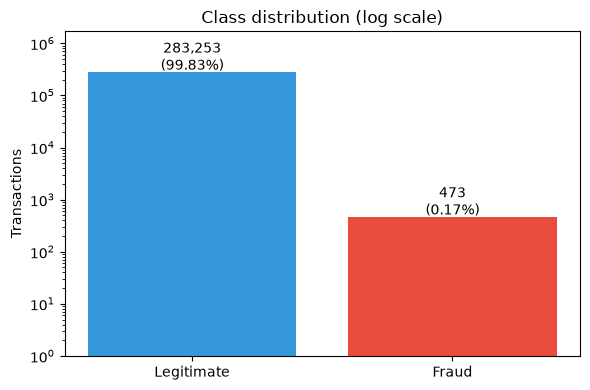

saved ../images/eda_class_distribution.png


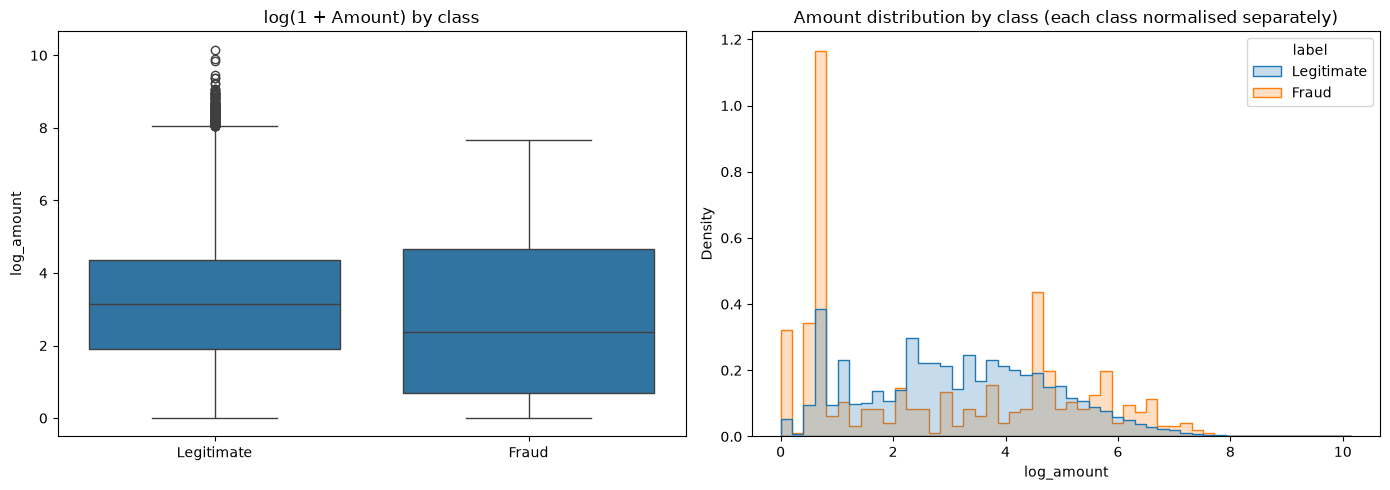

saved ../images/eda_amount_by_class.png


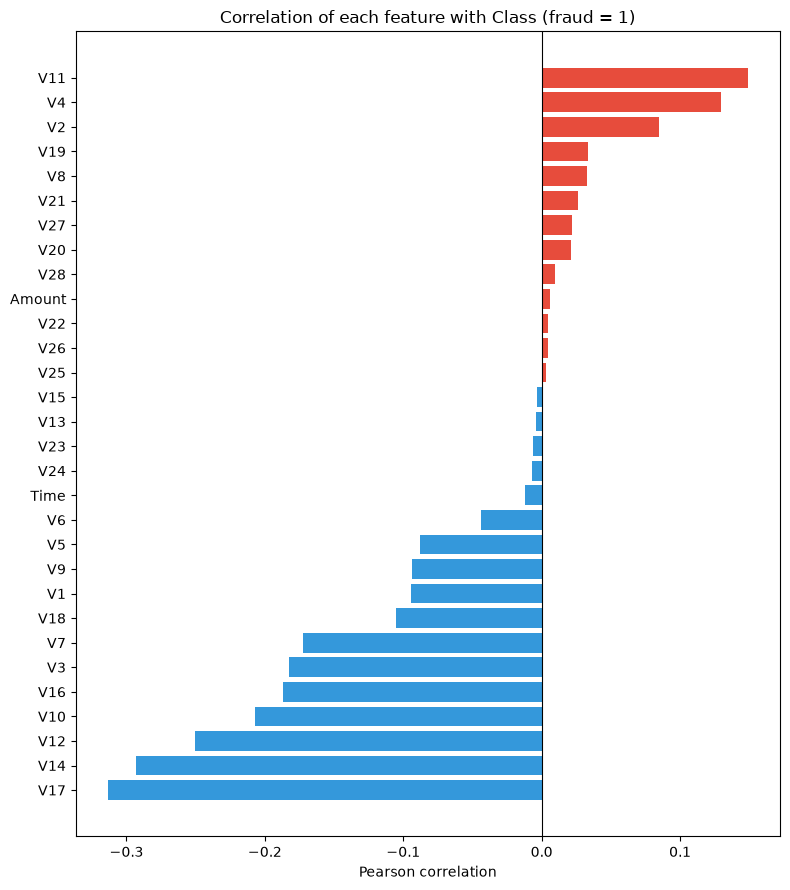

saved ../images/eda_feature_correlation.png


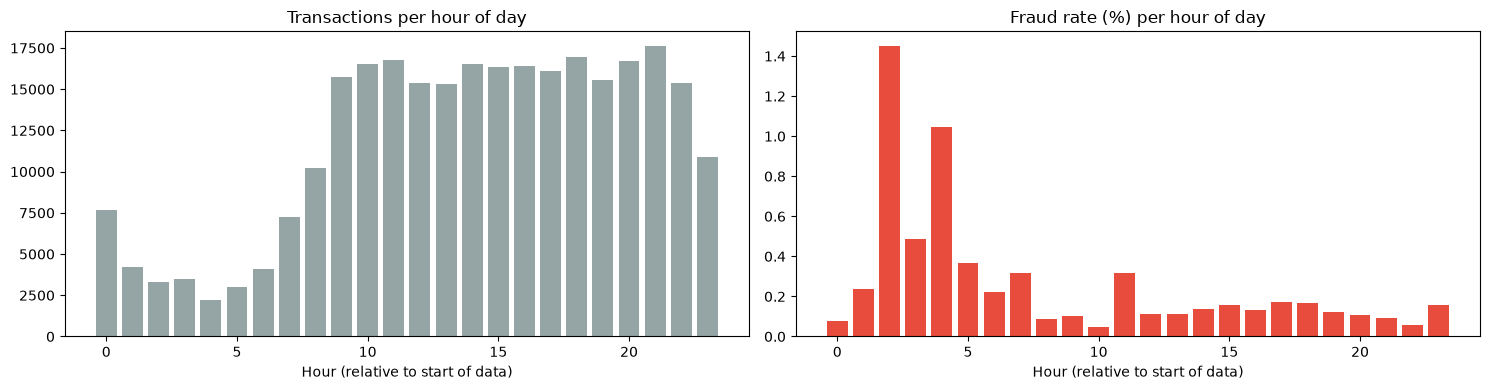

saved ../images/eda_fraud_rate_by_hour.png


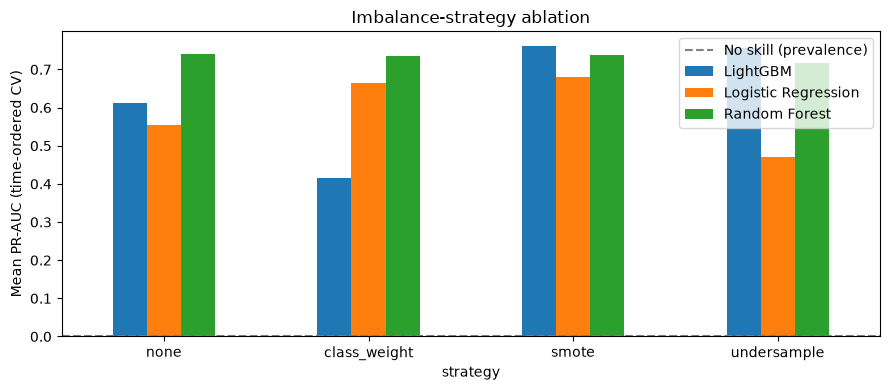

saved ../images/ablation_imbalance_strategy.png


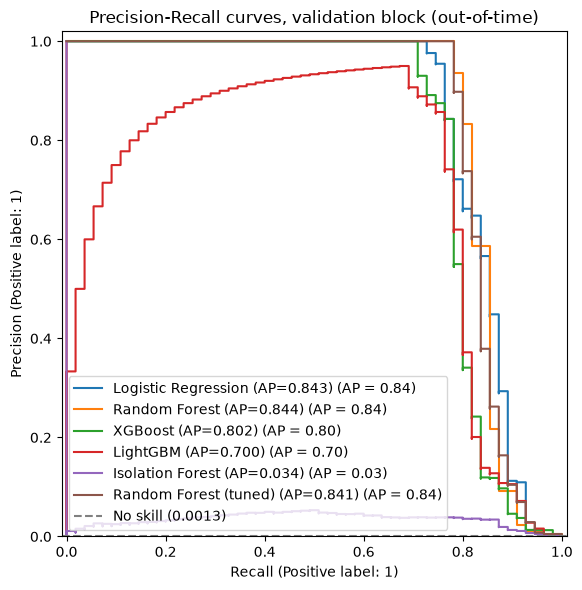

saved ../images/pr_curves_validation.png


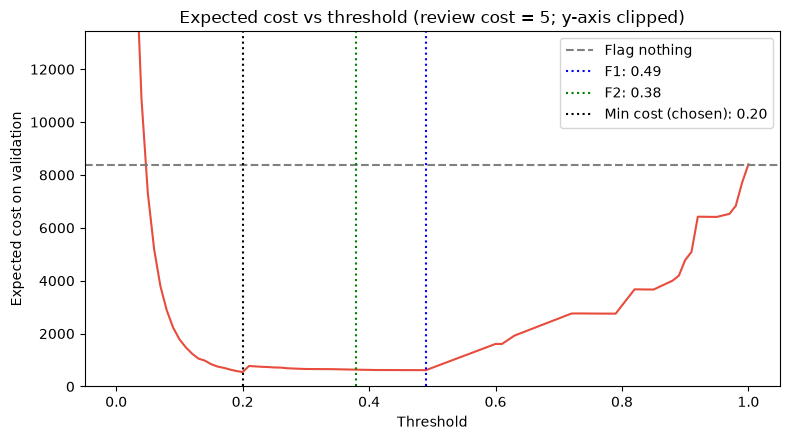

saved ../images/cost_vs_threshold.png
saved ../images/test_evaluation.png


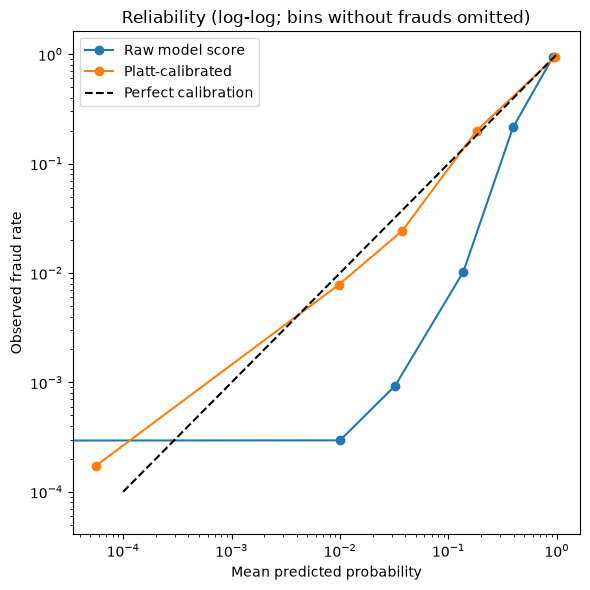

saved ../images/calibration_reliability.png


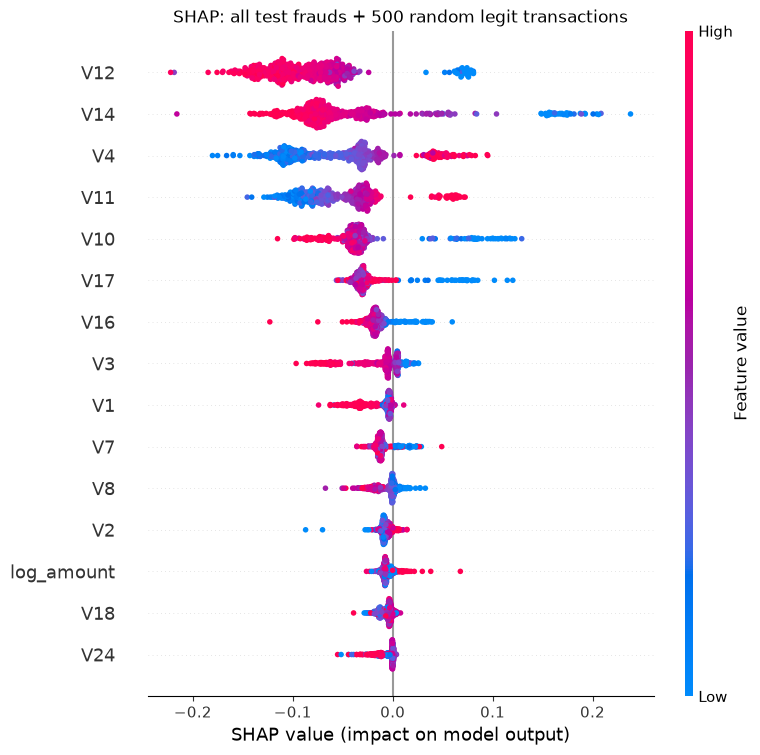

saved ../images/shap_summary.png


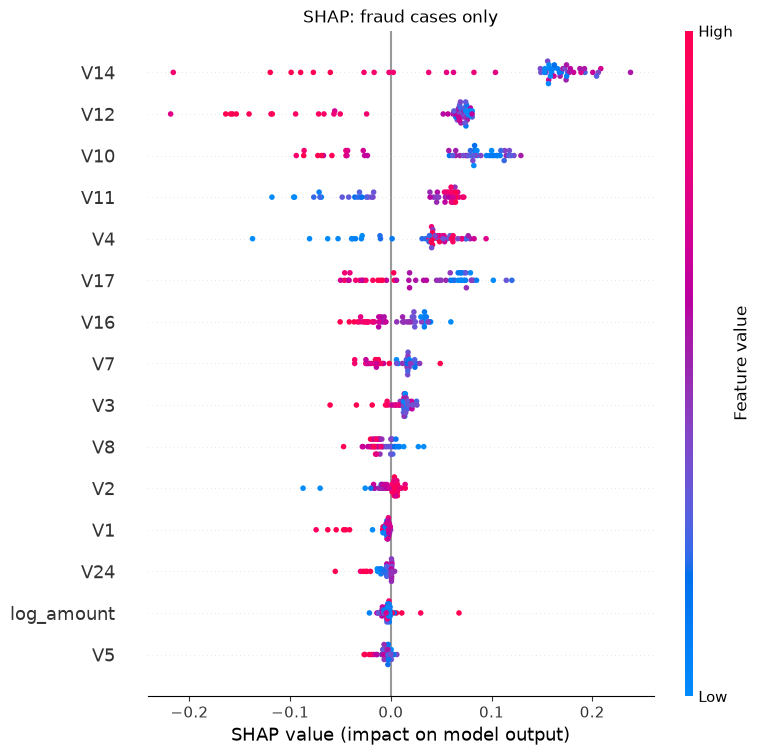

saved ../images/shap_summary_frauds_only.png


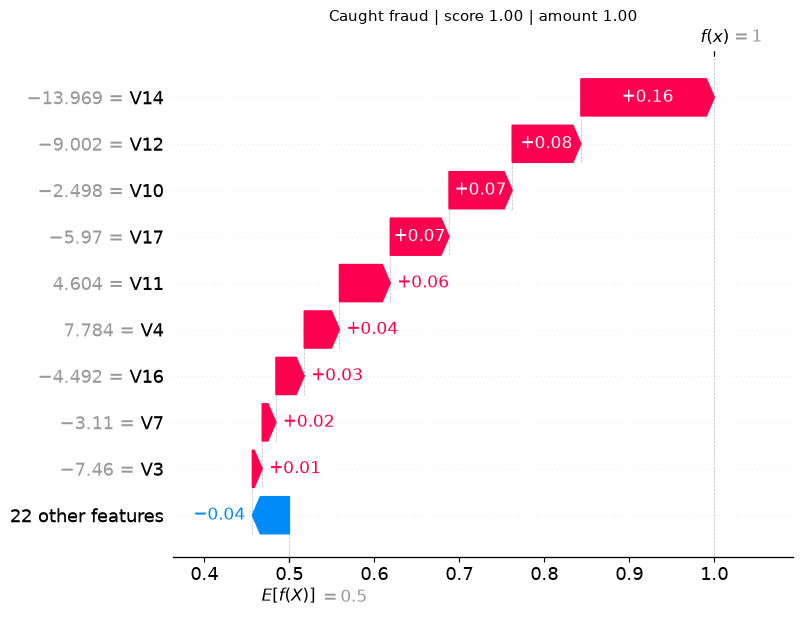

saved ../images/shap_waterfall_caught.png


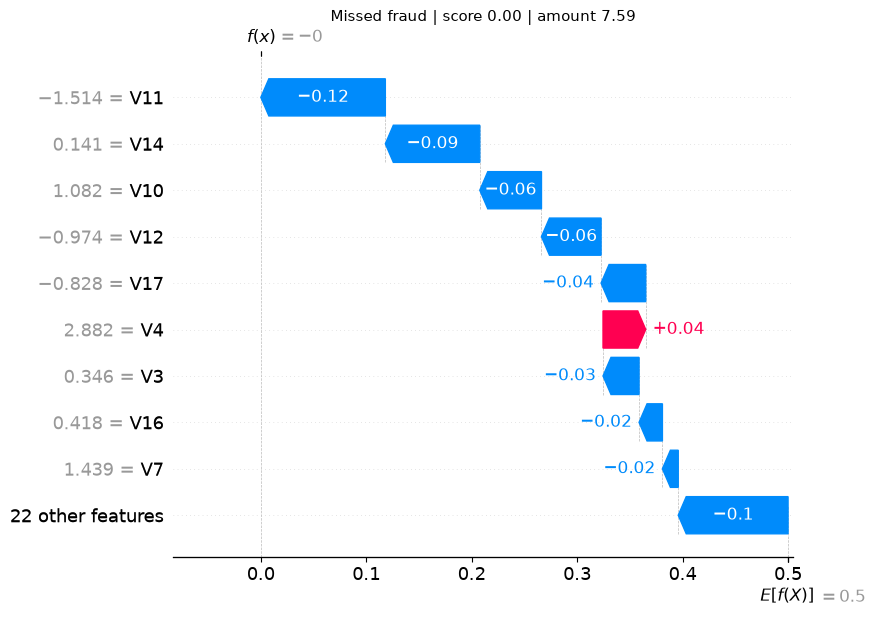

saved ../images/shap_waterfall_missed.png


In [37]:
from pathlib import Path
import shutil

IMG = Path('../images')                      # repo-level images/ folder (the notebook lives in notebook/)
IMG.mkdir(parents=True, exist_ok=True)


def save(name, tight=True):
    if tight:
        plt.tight_layout()
    plt.savefig(IMG / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close('all')                          # start every figure clean (SHAP plots draw on the current figure)
    print('saved', IMG / name)


label_map = {0: 'Legitimate', 1: 'Fraud'}

# ---- EDA ------------------------------------------------------------------------------------------------------
counts = df['Class'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Legitimate', 'Fraud'], counts.values, color=['#3498db', '#e74c3c'])
ax.set_yscale('log')
ax.set_ylim(1, counts.max() * 6)
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.1, f'{v:,}\n({100 * v / counts.sum():.2f}%)', ha='center')
ax.set_title('Class distribution (log scale)')
ax.set_ylabel('Transactions')
save('eda_class_distribution.png')

amt_df = pd.DataFrame({'label': df['Class'].map(label_map), 'log_amount': np.log1p(df['Amount'])})
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='label', y='log_amount', data=amt_df, order=['Legitimate', 'Fraud'], ax=ax[0])
ax[0].set_title('log(1 + Amount) by class')
ax[0].set_xlabel('')
sns.histplot(data=amt_df, x='log_amount', hue='label', hue_order=['Legitimate', 'Fraud'], stat='density',
             common_norm=False, bins=50, element='step', ax=ax[1])
ax[1].set_title('Amount distribution by class (each class normalised separately)')
save('eda_amount_by_class.png')

corr_cls = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()
plt.figure(figsize=(8, 9))
plt.barh(corr_cls.index, corr_cls.values, color=['#3498db' if v < 0 else '#e74c3c' for v in corr_cls.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each feature with Class (fraud = 1)')
plt.xlabel('Pearson correlation')
save('eda_feature_correlation.png')

hour = ((df['Time'] // 3600) % 24).astype(int).rename('hour')
bh = df.groupby(hour).agg(transactions=('Class', 'size'), frauds=('Class', 'sum'))
bh['fraud_rate_%'] = 100 * bh['frauds'] / bh['transactions']
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(bh.index, bh['transactions'], color='#95a5a6')
ax[0].set_title('Transactions per hour of day')
ax[0].set_xlabel('Hour (relative to start of data)')
ax[1].bar(bh.index, bh['fraud_rate_%'], color='#e74c3c')
ax[1].set_title('Fraud rate (%) per hour of day')
ax[1].set_xlabel('Hour (relative to start of data)')
save('eda_fraud_rate_by_hour.png')

# ---- Modeling -------------------------------------------------------------------------------------------------
ax = pivot.plot(kind='bar', figsize=(9, 4), rot=0)
ax.axhline(y_train.mean(), color='gray', linestyle='--', label='No skill (prevalence)')
ax.set_ylabel('Mean PR-AUC (time-ordered CV)')
ax.set_title('Imbalance-strategy ablation')
ax.legend()
save('ablation_imbalance_strategy.png')

fig, ax = plt.subplots(figsize=(9, 6))
for model_label, model_scores in val_scores.items():
    if model_label == 'Dummy (prior)':
        continue
    PrecisionRecallDisplay.from_predictions(
        y_val, model_scores, name=f'{model_label} (AP={average_precision_score(y_val, model_scores):.3f})', ax=ax)
ax.axhline(y_val.mean(), color='gray', linestyle='--', label=f'No skill ({y_val.mean():.4f})')
ax.set_title('Precision-Recall curves, validation block (out-of-time)')
ax.set_ylim(0, 1.02)
ax.legend(loc='lower left')
save('pr_curves_validation.png')

plt.figure(figsize=(8, 4.5))
plt.plot(thr_grid, cost, color='#e74c3c')
plt.axhline(no_model_cost, color='gray', linestyle='--', label='Flag nothing')
for rule_label, rule_thr, color in [('F1', thr_f1, 'blue'), ('F2', thr_f2, 'green'), ('Min cost (chosen)', thr_cost, 'black')]:
    plt.axvline(rule_thr, color=color, linestyle=':', label=f'{rule_label}: {rule_thr:.2f}')
plt.ylim(0, max(no_model_cost, cost.min()) * 1.6)         # flagging everything costs far more; clip so the optimum is visible
plt.xlabel('Threshold')
plt.ylabel('Expected cost on validation')
plt.title(f'Expected cost vs threshold (review cost = {REVIEW_COST:g}; y-axis clipped)')
plt.legend()
save('cost_vs_threshold.png')

if Path('model_evaluation.png').exists():            # written by the test-evaluation cell (Step 26)
    shutil.copy('model_evaluation.png', IMG / 'test_evaluation.png')
    print('saved', IMG / 'test_evaluation.png')

# ---- Calibration ----------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))
for curve_label, probs in [('Raw model score', final_test), ('Platt-calibrated', cal_test)]:
    g = reliability(y_t, probs)
    g = g[g['frauds'] > 0]                                           # zero-fraud bins cannot be drawn on a log axis
    ax.plot(g['mean_predicted'], g['observed_rate'], 'o-', label=curve_label)
ax.plot([1e-4, 1], [1e-4, 1], 'k--', label='Perfect calibration')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed fraud rate')
ax.set_title('Reliability (log-log; bins without frauds omitted)')
ax.legend()
save('calibration_reliability.png')

# ---- Explainability -------------------------------------------------------------------------------------------
for fname, title, mask in [('shap_summary.png', 'SHAP: all test frauds + 500 random legit transactions',
                            np.ones(len(X_shap), dtype=bool)),
                           ('shap_summary_frauds_only.png', 'SHAP: fraud cases only', is_fraud_row)]:
    shap.summary_plot(sv.values[mask], X_shap[mask], max_display=15, show=False)
    plt.title(title)
    save(fname, tight=False)

for fname, group, cases in [('shap_waterfall_caught.png', 'Caught fraud', tp_df),
                            ('shap_waterfall_missed.png', 'Missed fraud', fn_df)]:
    if len(cases):                                   # highest-scoring caught fraud / lowest-scoring missed fraud
        row_label, row = cases.index[0], cases.iloc[0]
        shap.plots.waterfall(fraud_explanation(X_test.loc[[row_label]])[0], max_display=10, show=False)
        plt.title(f"{group} | score {row['score']:.2f} | amount {row['Amount']:.2f}", fontsize=11)
        save(fname, tight=False)

In [38]:
import json
from datetime import date
from importlib import metadata

MODEL_DIR, APP_DIR, README = Path('../model'), Path('../app'), Path('../README.md')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
APP_DIR.mkdir(parents=True, exist_ok=True)

# 1) Compressed copy of the bundle for the repo (random forests compress well) + the demo sample for the app
bundle_path = MODEL_DIR / 'fraud_model_bundle.joblib'
joblib.dump(joblib.load('fraud_model_bundle.joblib'), bundle_path, compress=3)
shutil.copy('sample.csv', APP_DIR / 'sample.csv')
size_mb = bundle_path.stat().st_size / 1e6
print(f'{bundle_path}: {size_mb:.1f} MB' + ("  <- above GitHub's 100 MB limit: use Git LFS or a release asset" if size_mb > 95 else ''))


# 2) Library versions: a pickled model only loads reliably with the versions it was trained with
def dist_version(*names):
    for name in names:
        try:
            return metadata.version(name)
        except metadata.PackageNotFoundError:
            continue
    return None


LIBS = {'numpy': ('numpy',), 'pandas': ('pandas',), 'scikit-learn': ('scikit-learn',),
        'imbalanced-learn': ('imbalanced-learn',), 'xgboost': ('xgboost', 'xgboost-cpu'),
        'lightgbm': ('lightgbm',), 'shap': ('shap',)}
versions = {lib: dist_version(*names) for lib, names in LIBS.items()}

pins = [f'{lib}=={v}' for lib, v in versions.items() if v]
for pkg in ['scipy', 'matplotlib', 'seaborn', 'joblib', 'streamlit']:
    pins.append(f'{pkg}=={dist_version(pkg)}' if dist_version(pkg) else pkg)
req_path = Path('../requirements.txt')
if not req_path.exists():
    req_path.write_text('\n'.join(pins) + '\n')
    print('wrote', req_path)
else:
    print(req_path, 'already exists and was not overwritten. Versions used for training:')
print('\n'.join(pins))


# 3) metrics.json for the app's "Model card" tab
def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return None if np.isnan(x) else float(x)
    return x


metrics_out = {
    'created': str(date.today()),
    'model_name': final_name,
    'imbalance_strategy': IMBALANCE,
    'threshold': float(thr_final),
    'review_cost': float(REVIEW_COST),
    'dataset': {'rows_after_dedup': int(len(df)), 'frauds': int(df['Class'].sum()),
                'splits': split_summary.reset_index().rename(columns={'index': 'block'}).to_dict(orient='records')},
    'test_block': {'transactions': int(len(y_t)), 'frauds': int(y_t.sum()),
                   'tp': res['tp'], 'fp': res['fp'], 'fn': res['fn'], 'tn': res['tn']},
    'test_metrics': ci.to_dict(orient='index'),
    'protocol_comparison': protocol.reset_index().rename(columns={'index': 'protocol'}).to_dict(orient='records'),
    'model_ranking': ranking.reset_index().rename(columns={'index': 'model'}).to_dict(orient='records'),
    'ablation': ablation.to_dict(orient='records'),
    'versions': versions,
}
(MODEL_DIR / 'metrics.json').write_text(json.dumps(jsonable(metrics_out), indent=2), encoding='utf-8')
print('wrote', MODEL_DIR / 'metrics.json')


# 4) Results block for the README
def md_table(frame, index_name='', int_cols=()):
    cols = [index_name] + [str(c) for c in frame.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    for idx, row in frame.iterrows():
        cells = [str(idx)]
        for col, v in row.items():
            cells.append(str(int(v)) if col in int_cols else f'{v:.3f}' if isinstance(v, (float, np.floating)) else str(v))
        lines.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(lines)


pretty = {'pr_auc': 'PR-AUC', 'roc_auc': 'ROC-AUC', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1',
          'mcc': 'MCC', 'fraud_value_caught_%': 'Fraud value caught (%)', 'test_frauds': 'Test frauds'}
ci_md = ci.rename(index=pretty, columns={'estimate': 'Estimate', 'ci_low': '95% CI low', 'ci_high': '95% CI high'})
protocol_md = protocol.rename(columns=pretty)

fa_txt = f"{res['fp']} false alarm" + ('' if res['fp'] == 1 else 's')

block = f"""
**Final model:** {final_name} · imbalance handling: `{IMBALANCE}` · trained on the first 70 % of transactions by time  
**Decision threshold:** {thr_final:.3f} on the raw model score, chosen on the validation block by minimising expected cost (review cost assumed to be {REVIEW_COST:g} per alert; a missed fraud costs its transaction amount)

### Out-of-time test block: {len(y_t):,} transactions, {int(y_t.sum())} frauds

{md_table(ci_md, 'Metric')}

At the chosen threshold: {res['tp']} of {res['tp'] + res['fn']} frauds caught, {res['fn']} missed, {fa_txt}.

### Random split vs out-of-time split (same model, same threshold)

{md_table(protocol_md, 'Protocol', int_cols={'Test frauds'})}

### Model comparison on the validation block (baselines included)

{md_table(ranking, 'Model')}

### Imbalance-handling ablation (mean PR-AUC, time-ordered CV)

{md_table(pivot, 'Strategy')}

<sub>Generated by the notebook on {date.today()}.</sub>
"""
display(Markdown(block))

START, END = '<!-- RESULTS:START -->', '<!-- RESULTS:END -->'
text = README.read_text(encoding='utf-8') if README.exists() else ''
if START in text and END in text:
    head, rest = text.split(START, 1)
    tail = rest.split(END, 1)[1]
    README.write_text(head + START + '\n' + block.strip() + '\n' + END + tail, encoding='utf-8')
    print('README results block updated')
else:
    Path('../results_block.md').write_text(block, encoding='utf-8')
    print('No RESULTS markers found in README.md: block saved to ../results_block.md, paste it into the README')

../model/fraud_model_bundle.joblib: 4.4 MB
../requirements.txt already exists and was not overwritten. Versions used for training:
numpy==2.5.3
pandas==3.0.6
scikit-learn==1.9.1
imbalanced-learn==0.14.2
xgboost==3.4.1
lightgbm==4.7.0
shap==0.52.0
scipy==1.18.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
streamlit==1.64.0
wrote ../model/metrics.json



**Final model:** Random Forest · imbalance handling: `smote` · trained on the first 70 % of transactions by time  
**Decision threshold:** 0.200 on the raw model score, chosen on the validation block by minimising expected cost (review cost assumed to be 5 per alert; a missed fraud costs its transaction amount)

### Out-of-time test block: 42,559 transactions, 52 frauds

| Metric | Estimate | 95% CI low | 95% CI high |
|---|---|---|---|
| PR-AUC | 0.777 | 0.653 | 0.882 |
| ROC-AUC | 0.962 | 0.924 | 0.993 |
| Precision | 0.500 | 0.390 | 0.606 |
| Recall | 0.769 | 0.641 | 0.881 |
| F1 | 0.606 | 0.500 | 0.697 |
| MCC | 0.620 | 0.516 | 0.707 |
| Fraud value caught (%) | 71.825 | 35.822 | 97.756 |

At the chosen threshold: 40 of 52 frauds caught, 12 missed, 40 false alarms.

### Random split vs out-of-time split (same model, same threshold)

| Protocol | Test frauds | ROC-AUC | PR-AUC | Precision | Recall | F1 | Fraud value caught (%) |
|---|---|---|---|---|---|---|---|
| Random stratified split (80/20) | 95 | 0.965 | 0.800 | 0.726 | 0.811 | 0.766 | 74.382 |
| Out-of-time split (last 15%) | 52 | 0.962 | 0.777 | 0.500 | 0.769 | 0.606 | 71.825 |

### Model comparison on the validation block (baselines included)

| Model | PR-AUC | ROC-AUC |
|---|---|---|
| Random Forest | 0.844 | 0.987 |
| Logistic Regression | 0.843 | 0.979 |
| Random Forest (tuned) | 0.841 | 0.987 |
| XGBoost | 0.802 | 0.987 |
| LightGBM | 0.700 | 0.974 |
| Isolation Forest | 0.034 | 0.947 |
| Dummy (prior) | 0.001 | 0.500 |

### Imbalance-handling ablation (mean PR-AUC, time-ordered CV)

| Strategy | LightGBM | Logistic Regression | Random Forest |
|---|---|---|---|
| none | 0.612 | 0.555 | 0.741 |
| class_weight | 0.416 | 0.663 | 0.735 |
| smote | 0.762 | 0.679 | 0.737 |
| undersample | 0.756 | 0.469 | 0.717 |

<sub>Generated by the notebook on 2026-10-25.</sub>


No RESULTS markers found in README.md: block saved to ../results_block.md, paste it into the README
